# <center> Сегментация клиентов онлайн магазина подарков

## Постановка задачи


<center> <img src=https://salesupnow.ru/storage/app/media/pipeople.png align="right" width="300"/> </center>

Маркетинг — неотъемлемая часть любого бизнеса. Для повышения прибыли компании важно понимать своего клиента, его пожелания и предпочтения. С появлением электронной коммерции, или онлайн-продаж, стало намного проще собирать данные о клиентах, анализировать их, находить закономерности и реализовывать маркетинговые кампании.

Большинство интернет-магазинов используют инструменты веб-аналитики, чтобы отслеживать просмотры страниц, количество и поведение посетителей и коэффициент отказов. Но отчёта из Google Analytics или аналогичной системы может быть недостаточно для полного понимания того, как клиенты взаимодействуют с сайтом. Компаниям важно иметь возможность быстро и точно реагировать на перемены в поведении клиентов, создавая инструменты, которые обнаруживают эти изменения практически в режиме реального времени.

Машинное обучение помогает поисковой системе анализировать огромное количество данных о посетителях платформы, узнавать модели поведения профессиональных покупателей, определять категорию клиентов (например, лояльные/перспективные/новички/спящие/ушедшие) и выбирать правильную стратегию взаимодействия с ними.

Стоит также отметить, что компании, использующие машинное обучение на своих платформах электронной коммерции, могут постоянно повышать эффективность бизнес-процессов: настраивать товарную выборку персонально для каждого покупателя и предлагать выгодную цену в соответствии с бюджетом клиента и т. д. Эта задача относится к категории построения рекомендательных систем, речь о которых пойдёт в следующем разделе нашего курса.

> Как правило, наборы данных для электронной коммерции являются частной собственностью и, следовательно, их трудно найти среди общедоступных данных. Однако [The UCI Machine Learning Repository](http://archive.ics.uci.edu/ml/index.php)  создал набор данных, содержащий фактические транзакции за 2010 и 2011 годы. С ним нам как раз и предлагается поработать в этом кейсе. 

> В нашем распоряжении будет набор данных, который содержит все транзакции, произошедшие в период с 01/12/2010 по 09/12/2011 для базирующейся в Великобритании компании, занимающейся онлайн-розничной торговлей. Компания в основном продает уникальные подарки на все случаи жизни. Многие клиенты компании являются оптовиками.


**Бизнес-задача:** произвести сегментацию существующих клиентов, проинтерпретировать эти сегменты и определить стратегию взаимодействия с ними.

**Техническая задача для вас как для специалиста в Data Science:** построить модель кластеризации клиентов на основе их покупательской способности, частоты заказов и срока давности последней покупки, определить профиль каждого из кластеров.

**Основные цели проекта:**
1. Произвести предобработку исходного набора данных о транзакциях.
2. Провести разведывательный анализ данных и выявить основные закономерности.
3. Сформировать набор данных о характеристиках каждого из уникальных клиентов.
4. Построить несколько моделей машинного обучения, решающих задачу кластеризации клиентов, определить количество кластеров и проинтерпретировать их.
5. Выводы и общие комментарии о проведенной работе.

## 1. Исследование структуры данных, базовый анализ и предобработка данных.

In [285]:
# Импортируем необходимые библиотеки:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objs as go

from sklearn import pipeline
from sklearn import preprocessing
from sklearn.decomposition import TruncatedSVD
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

from sklearn.cluster import SpectralClustering
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.cluster import AgglomerativeClustering

from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score


Первым делом посмотрим, с какими данными нам предстоит работать. Далее произвести базовую предобработку данных, переведя признаки в необходимые для дальнейшей работы форматы.

Вызываем наши данные:

In [ ]:
data = pd.read_csv('data/data.csv', sep=',', encoding="ISO-8859-1", dtype={'CustomerID': str,'InvoiceNo': str})
print('Размер нашего датасета:', data.shape)
data.head()

Размер нашего датасета: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850,United Kingdom


Датасет состоит из более полумиллиона транзакций и характеризуется следующими восьмью признаками:
* InvoiceNo — номер счёта-фактуры (уникальный номинальный шестизначный номер, присваиваемый каждой транзакции; буква "C" в начале кода указывает на отмену транзакции);
* Stock Code — код товара (уникальное пятизначное целое число, присваиваемое каждому отдельному товару);
* Description — название товара;
* Quantity — количество каждого товара за транзакцию; 
* InvoiceDate — дата и время выставления счёта/проведения транзакции;
* UnitPrice — цена за единицу товара в фунтах стерлингов;
* CustomerID — идентификатор клиента (уникальный пятизначный номер, однозначно присваиваемый каждому клиенту);
* Country — название страны, в которой проживает клиент.

Посмотрим на структуру и типизацию признаков:

In [713]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  object 
 7   Country      541909 non-null  object 
dtypes: float64(1), int64(1), object(6)
memory usage: 33.1+ MB


In [714]:
# Видим, что среди категориальных признаков присутствует временной признак, указывающий дату и время, когда произошла транзакция.
# Преобразуем признак ['InvoiceDate'] в формат datetime, также при выгрузке  данных можно было сразу указать какой признак считается временным (и сразу преобразовать в формат datetime).
data['InvoiceDate'] = pd.to_datetime(data['InvoiceDate'],)# format="%m %d %Y %H:%M")

*В своей структуре данные содержат 8 признаков и 541 909 наблюдений. Из них один признак даты, пять категориальных (один из из которых текстовый - название товара) и два числовых (количественных) признака.*

После преобразования в признаке ['InvoiceDate'] посмотрим в каком временном интервале представлен датасет 

In [715]:
# Для этого воспользуемся методом describe(), чтобы вывести основные статистические характеристики.
display(data.describe(include=['datetime']))
print('Временной период лежит в интервале от {} до {}'.format(data.InvoiceDate.min(), data.InvoiceDate.max()))

,InvoiceDate
count,541909
mean,2011-07-04 13:34:57.156386048
min,2010-12-01 08:26:00
25%,2011-03-28 11:34:00
50%,2011-07-19 17:17:00
75%,2011-10-19 11:27:00
max,2011-12-09 12:50:00


Временной период лежит в интервале от 2010-12-01 08:26:00 до 2011-12-09 12:50:00


Присмотримся по внимательней к признаку `InvoiceNo`. В этом признаке имеется как значения цифрового шифра, так и значения со смешенным шифром в виде букв и цифр. Разделим эти значения и поймем их смысл.

In [716]:
# Воспользуемся для этого регулярными выражениями
import re # вызываем библиотеку регулярных выражений для корректного вида данных
data_1 = data.copy()
# Создадим вспомогательные признаки
data_1['digital_component_Invoice'] = data_1['InvoiceNo'].apply(lambda x: x if type(x)!= str else (''.join(re.findall(r'(\d+)',x)))) # если \b, то возьмем только значение с цифровым шифром, а, если без \b, то откинем букву и возьмем цифровой шифр
data_1['letter_component_Invoice'] = data_1['InvoiceNo'].apply(lambda x: x if type(x)!= str else (''.join(re.findall(r'(\D+)',x)))) 
data_1 = data_1.iloc[:,[0,8,9,1,2,3,4,5,6,7]] # новый порядок признаков
# Так же сразу преобразуем ['digital_component_Invoice'] в числовой формат
data_1.digital_component_Invoice=pd.to_numeric(data_1.digital_component_Invoice, errors='coerce')
# Посмотрим какие уникальные значения в новом признаке текстового составляющего шифра
print("Значение, которые встречаются в признаке ['letter_component_Invoice']:",data_1['letter_component_Invoice'].unique())
# Теперь посмотрим, что же у нас скрывается под invoice-ом с литерой 'A'
data_1[data_1['letter_component_Invoice']=='A']

Значение, которые встречаются в признаке ['letter_component_Invoice']: ['' 'C' 'A']


,InvoiceNo,digital_component_Invoice,letter_component_Invoice,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299982,A563185,563185,A,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom
299983,A563186,563186,A,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,563187,A,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


*Итак, мы видим в транзакциях/invoice-сах с литерой 'A' списание в никуда, какого-то долга привязанного скорее всего к несуществующему товару B (возможно это какой-то сток), о котором указано в описании товара (признак `Description`: "Adjust bad debt" - "Корректировка безнадежной задолженности"). Причем сначала товар списывается, две последующие операции списания с отрицательной ценой. Операции производятся с разницей в 1 минуту. Эти данные нам точно не нужны. Но стоит отметить следующие моменты: товар обозначен одной буквой и списывается в никуда в `CustomerID`: 'NaN'. Такие моменты увидим и в дальнейшем.*

*Остальные инвойсы с цифровым шифром без латинских букв имеют характер отгрузок с положительным количеством товара, а с латинской буквой C имеют характер приходов/возвратов с отрицательным количеством товара.*

Исследуем данные на предмет пропусков. Где есть пропущенные значения? Сколько их?

[('Description', 1454), ('CustomerID', 135080)]

CustomerID     24.93
Description     0.27
dtype: float64


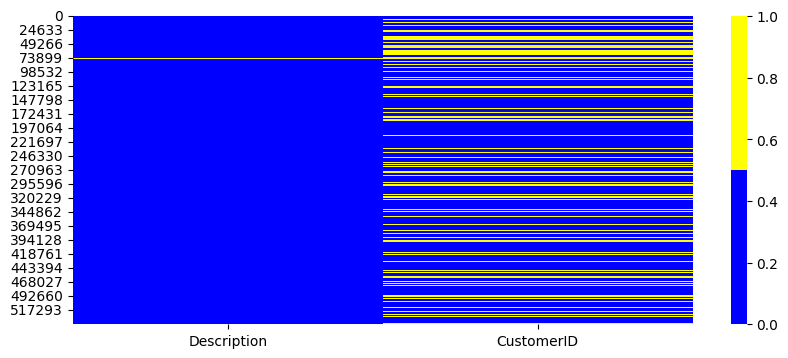

In [717]:
# Найдем признаки с пропущенными данными с помощью созданной функции.
def possible_empty_values(data): # функция возможных пропущенных значений (пропусков)
    list_count_empty=list()
    for col in data.columns:
        count_complete = data[col].count()
        if count_complete!=data.shape[0]:
            count_empty = data.shape[0] - count_complete
            list_count_empty.append((col, count_empty))
    return list_count_empty

list_count_empty = possible_empty_values(data_1)
display(list_count_empty)
# Посмотрим на них также в процентном соотношении и визуализируем с помощью тепловой диаграммы
data_pr = data_1.isnull().mean()*100
print(data_pr[data_pr>0].sort_values(ascending=False).round(2))
colors = ['blue', 'yellow'] 
fig = plt.figure(figsize=(10, 4))
ax = sns.heatmap(data_1[data_pr[data_pr>0].index].isnull(),
    cmap=sns.color_palette(colors))

Посмотрим чуть более подробнее на данные с неопределенным клиентом (`CustomerID`:NaN) и с неопределенным товаром(`Description`:NaN)

In [718]:
# Посмотрим на основные статистические характеристики выборки с 'CustomerID':NaN.
# Для этого воспользуемся методом describe()
display(data[data['CustomerID'].isna()].describe(include='all'))
# Посмотрим поближе, что за Invoice 573585 с 1114 количеством строк
display(data[(data['InvoiceNo']=='573585')&(data['Quantity']<0)])
display(data[(data['InvoiceNo']=='573585')])
# Посмотрим ещё проводки такой же даты как Invoice 573585
display(data[(data['InvoiceDate']>'2011-10-31 12:00:00')&(data['InvoiceDate']<='2011-10-31 23:59:00')][:1])
# Взглянем также для примера на товар с кодом 22139
data[data['StockCode']=='22139']#['Description'].unique()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,135080,135080,133626,135080.000000,135080,135080.000000,0,135080
unique,3710,3810,3554,NaN,NaN,NaN,0,9
top,573585,DOT,DOTCOM POSTAGE,NaN,NaN,NaN,NaN,United Kingdom
freq,1114,694,693,NaN,NaN,NaN,NaN,133600
mean,NaN,NaN,NaN,1.995573,2011-06-16 03:03:12.611637760,8.076577,NaN,NaN
min,NaN,NaN,NaN,-9600.000000,2010-12-01 11:52:00,-11062.060000,NaN,NaN
25%,NaN,NaN,NaN,1.000000,2011-02-21 18:10:00,1.630000,NaN,NaN
50%,NaN,NaN,NaN,1.000000,2011-06-27 15:27:00,3.290000,NaN,NaN
75%,NaN,NaN,NaN,3.000000,2011-10-11 16:37:00,5.450000,NaN,NaN
max,NaN,NaN,NaN,5568.000000,2011-12-09 10:26:00,17836.460000,NaN,NaN


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
430237,573585,11001,ASSTD DESIGN RACING CAR PEN,2,2011-10-31 14:41:00,3.29,NaN,United Kingdom
430238,573585,15036,ASSORTED COLOURS SILK FAN,15,2011-10-31 14:41:00,1.63,NaN,United Kingdom
430239,573585,15039,SANDALWOOD FAN,15,2011-10-31 14:41:00,1.63,NaN,United Kingdom
430240,573585,15056BL,EDWARDIAN PARASOL BLACK,1,2011-10-31 14:41:00,12.46,NaN,United Kingdom
430241,573585,15056N,EDWARDIAN PARASOL NATURAL,1,2011-10-31 14:41:00,12.46,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
431346,573585,90209C,PINK ENAMEL+GLASS HAIR COMB,3,2011-10-31 14:41:00,2.07,NaN,United Kingdom
431347,573585,90214S,"LETTER ""S"" BLING KEY RING",1,2011-10-31 14:41:00,0.83,NaN,United Kingdom
431348,573585,DOT,DOTCOM POSTAGE,1,2011-10-31 14:41:00,2019.05,NaN,United Kingdom
431349,573585,gift_0001_20,Dotcomgiftshop Gift Voucher £20.00,1,2011-10-31 14:41:00,16.67,NaN,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
428766,573499,21192,check,-164,2011-10-31 12:01:00,0.0,NaN,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
106,536381,22139,RETROSPOT TEA SET CERAMIC 11 PC,23,2010-12-01 09:41:00,4.25,15311,United Kingdom
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.00,NaN,United Kingdom
6392,536942,22139,amazon,15,2010-12-03 12:08:00,0.00,NaN,United Kingdom
6885,536982,22139,RETROSPOT TEA SET CERAMIC 11 PC,10,2010-12-03 14:27:00,11.02,NaN,United Kingdom
7203,537011,22139,NaN,-5,2010-12-03 15:38:00,0.00,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
538411,581405,22139,RETROSPOT TEA SET CERAMIC 11 PC,1,2011-12-08 13:50:00,4.95,13521,United Kingdom
539531,581439,22139,RETROSPOT TEA SET CERAMIC 11 PC,1,2011-12-08 16:30:00,10.79,NaN,United Kingdom
540441,581486,22139,RETROSPOT TEA SET CERAMIC 11 PC,6,2011-12-09 09:38:00,4.95,17001,United Kingdom
541387,581498,22139,RETROSPOT TEA SET CERAMIC 11 PC,2,2011-12-09 10:26:00,10.79,NaN,United Kingdom


*Видим, что наиболее частой счет-фактурой (Invoice-ом) является 573585 с 1114 количеством строк, а наиболее частым продуктом является DOT - DOTCOM POSTAGE (почтовые расходы). Также видим, что в `Quantity` есть отрицательные количества (приход на склад, возврат товара), так и положительные количества (отгрузка, списание).*

*Пронаблюдав за поведением проводок в никуда, т.е. списания товара (причем в одной проводке могут списывать и товары, и услуги как это показано выше на примере товара DOT - DOTCOM POSTAGE) и заведение излишков из ниоткуда (пример проводки излишков с нулевой ценой в Invoice 573499, что у нас запрещено (вводить с нулевой ценой излишки на сток)) можно сделать вывод, что это движения товаров по выравниванию стока, т.е. инвентаризационные операции - проводки списания, заведение излишков (скорее всего проходит выборочная инвентаризация, т.к. отгрузки в эти дни у них проходят, и движение по стоку не останавливается). С этим же связано и переименование товара или же отсутствие названия в признаке `Description` соответствующему коду товаров (который был уже давно заведен). Выше приведен пример такого товара по коду 22139.*

*В связи с вышеизложенным эти транзакции не являются настоящими продажами и эти данные нужно удалить.*

In [719]:
data = data[~data['CustomerID'].isna()]
data_1 = data_1[~data_1['CustomerID'].isna()]

Теперь займемся дубликатам.

In [720]:
# Проверяем имеются ли полные дубликаты в наших данных
dublicat=data.duplicated(subset=data.columns)
# Находим количество дубликатов
print(f'Число найденных дубликатов: {data[dublicat].shape[0]}')
#display(data[data.duplicated(keep=False)][:40])
# Удаляем найденные дубликаты
data = data.drop_duplicates(subset=data.columns).reset_index(drop=True)
data_1 = data_1.drop_duplicates(subset=data_1.columns).reset_index(drop=True)
print(f'Число записей после удаления дубликатов составляет: {data.shape}')
print(f'Число записей вов вспомогательном датасете после удаления дубликатов составляет: {data_1.shape}')

Число найденных дубликатов: 5225
Число записей после удаления дубликатов составляет: (401604, 8)
Число записей вов вспомогательном датасете после удаления дубликатов составляет: (401604, 10)


Как мы уже отмечали выше, что в признаке код товара у нас могут возникать не только продукты с закодированном смешенным (цифровым и буквенным) или просто цифровым шифром, но и почему-то услуги или другие движения по стоку они обозначены заглавными латинскими буквами. Специальные операции не характеризуют покупательскую способность клиентов, так как не относятся напрямую к их покупкам, поэтому такие записи нам не нужны. Удалим все специальные товары из таблицы.

Воспользуемся помощью str.contains() для поиска подстрок в признаке `StockCode`. В качестве шаблона для поиска используйте строку '^[a-zA-Z]+'. Параметр regex установим в значение True.

In [721]:
special_operation = data['StockCode'].str.contains(pat='^[A-Za-z]', regex=True)
display(data[special_operation]['StockCode'].unique())
display(data[special_operation]['Description'].unique())
display(data[special_operation])

array(['POST', 'D', 'C2', 'M', 'BANK CHARGES', 'PADS', 'DOT', 'CRUK'],
      dtype=object)

array(['POSTAGE', 'Discount', 'CARRIAGE', 'Manual', 'Bank Charges',
       'PADS TO MATCH ALL CUSHIONS', 'DOTCOM POSTAGE', 'CRUK Commission'],
      dtype=object)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
45,536370,POST,POSTAGE,3,2010-12-01 08:45:00,18.00,12583,France
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527,United Kingdom
386,536403,POST,POSTAGE,1,2010-12-01 11:27:00,15.00,12791,Netherlands
1097,536527,POST,POSTAGE,1,2010-12-01 13:04:00,18.00,12662,Germany
1386,536540,C2,CARRIAGE,1,2010-12-01 14:05:00,50.00,14911,EIRE
...,...,...,...,...,...,...,...,...
401195,581494,POST,POSTAGE,2,2011-12-09 10:13:00,18.00,12518,Germany
401243,C581499,M,Manual,-1,2011-12-09 10:28:00,224.69,15498,United Kingdom
401425,581570,POST,POSTAGE,1,2011-12-09 11:59:00,18.00,12662,Germany
401462,581574,POST,POSTAGE,2,2011-12-09 12:09:00,18.00,12526,Germany


Среди всех специальных товаров присмотримся к товару D.

In [722]:
display(data[data['StockCode']=='D'])
data[(data['StockCode']=='D')&(data['Quantity']>0)]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527,United Kingdom
6596,C537164,D,Discount,-1,2010-12-05 13:21:00,29.29,14527,United Kingdom
9977,C537597,D,Discount,-1,2010-12-07 12:34:00,281.00,15498,United Kingdom
12450,C537857,D,Discount,-1,2010-12-08 16:00:00,267.12,17340,United Kingdom
20274,C538897,D,Discount,-1,2010-12-15 09:14:00,5.76,16422,United Kingdom
...,...,...,...,...,...,...,...,...
357248,C577227,D,Discount,-1,2011-11-18 12:06:00,19.82,14527,United Kingdom
357249,C577227,D,Discount,-1,2011-11-18 12:06:00,16.76,14527,United Kingdom
367994,C578239,D,Discount,-1,2011-11-23 12:29:00,26.33,14912,Italy
384059,C579884,D,Discount,-1,2011-11-30 17:34:00,20.53,14527,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country


*В описании к этому товару в признаке `Description` указано, что он Discount (буквально скидочный товар). Но по поведению его движений на стоке он напонинает брак, который не приняли клиенты, т.е. он ни разу не отгружался клиентам, приходуется он на сток только с возвратных счет-фактур (invoice) от разных клиентов с постоянно разными ценами.*

*И вообще рассматривая и анализируя транзакции приходишь к выводу, что данные переданы с какой-то одноуровневой системы управления складом, где нет отдельных стоков для хорошего товара и бракованного (бракованный просто заводится под отдельным буквенным шифром D), где бухгалтерские задолженности за услуги списываются вперемешку с недостачами, где на общем стоке накапливается задолжность за разные услуги, долги от клиентов также заводятся как продукт.*

Теперь исключим из данных все эти специальные товары. Всё это не относится к продажам.

In [723]:
data = data[~special_operation]
data_1 = data_1[~special_operation]

Займемся возвратами от клиентов (отрицательными значениями в признаке `Quantity`).

In [724]:
# Для этого нам поможет вспомогательный датасет data_1
storno_inv = set(data_1[data_1['letter_component_Invoice']=='C']['digital_component_Invoice'])
print(f"Всего возвратных инвойсов: {len(storno_inv)}шт. Это занимает {data_1[data_1['digital_component_Invoice'].isin(storno_inv)].shape[0]} \
строк в оставшемся датасете или {(data_1[data_1['digital_component_Invoice'].isin(storno_inv)].shape[0]/data_1.shape[0]*100):.2f}%.")
storno_cus = set(data_1[data_1['letter_component_Invoice']=='C']['CustomerID'])
print(len(storno_cus),'клиента возвращали товар.')
storno_prod = set(data_1[data_1['letter_component_Invoice']=='C']['StockCode'])
storno_quan = set(data_1[data_1['letter_component_Invoice']=='C']['Quantity'])
print(f"Было возвращено {len(storno_prod)} разных продуктовых позиции в общем количестве {abs(data_1[data_1['letter_component_Invoice']=='C']['Quantity'].sum())}шт. \
или {(abs(data_1[data_1['letter_component_Invoice']=='C']['Quantity'].sum())/data_1[data_1['Quantity']>0]['Quantity'].sum())*100:.2f}% (в процентном отношении от общего количества отгруженного товара).")
#len(storno_prod)
# 5,19 - чуть больше размера статистической ошибки (статистической значимости α)

Всего возвратных инвойсов: 3383шт. Это занимает 8506 строк в оставшемся датасете или 2.13%.
1534 клиента возвращали товар.
Было возвращено 1915 разных продуктовых позиции в общем количестве 267711шт. или 5.19% (в процентном отношении от общего количества отгруженного товара).


Сначала посмотрим на полные возвраты, т.е. сколько отгружено по счет-фактуре столько и возвращено.

In [ ]:
# Итак, создадим 2-а датасета.
# Возвратный датасет, в котором будет продукты отгруженные клиентам и возвращенные
storno = data_1[(data_1['CustomerID'].isin(storno_cus))&(data_1['StockCode'].isin(storno_prod))&(data_1['Quantity'].isin(list(storno_quan)))].reset_index()
# Датасет, в котором имеются подобные отгрузки, т.е. тем же клиентам, тот же продукт и в том же количестве
similar_shipments = data_1[(data_1['CustomerID'].isin(storno_cus))&(data_1['StockCode'].isin(storno_prod))&(data_1['Quantity'].isin(map(abs,list(storno_quan))))].reset_index()#|(data_1['Quantity'].isin(storno_quan))]
# Теперь найдем все подходящие пересечения собранные в storno
for_suitable = storno.merge(right=similar_shipments, on=['CustomerID', 'StockCode'], how='inner')
# Вводим ограничивающие условия: только инвойс-возврата старше инвоса-отрузки (или что тоже самое инвос-отрузки младше инвойса-возврата)
# и только полные возвраты
suitable = for_suitable[(for_suitable['digital_component_Invoice_x']>for_suitable['digital_component_Invoice_y'])&(-(for_suitable['Quantity_x'])==for_suitable['Quantity_y'])]
# Берем подходящих только первые вхождения, так как подборок подходящих комбинаций может быть несколько, т.е. убираем дубликаты
full_refunds_inv = suitable[(~suitable.duplicated(subset=['CustomerID', 'StockCode','Quantity_x','digital_component_Invoice_x'], keep='first'))&\
    (~suitable.duplicated(subset=['CustomerID', 'StockCode','Quantity_y','digital_component_Invoice_y'], keep='first'))]
# Рассмотрим полные возвраты внимательнее 
full_refunds_inv[full_refunds_inv['InvoiceDate_x']-full_refunds_inv['InvoiceDate_y']<='0 days 00:50:00'].sort_values(by='Quantity_y', ascending=False)

,index_x,InvoiceNo_x,digital_component_Invoice_x,letter_component_Invoice_x,StockCode,Description_x,Quantity_x,InvoiceDate_x,UnitPrice_x,CustomerID,Country_x,index_y,InvoiceNo_y,digital_component_Invoice_y,letter_component_Invoice_y,Description_y,Quantity_y,InvoiceDate_y,UnitPrice_y,Country_y
23038,401132,C581484,581484,C,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446,United Kingdom,401131,581483,581483,,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,United Kingdom
2198,37516,C541433,541433,C,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346,United Kingdom,37511,541431,541431,,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,United Kingdom
19045,306267,C572343,572343,C,22102,MIRROR MOSAIC T-LIGHT HOLDER,-720,2011-10-24 10:40:00,0.39,14607,United Kingdom,305980,572324,572324,,MIRROR MOSAIC T-LIGHT HOLDER,720,2011-10-24 09:52:00,0.39,United Kingdom
19043,306266,C572343,572343,C,22103,MIRROR MOSAIC T-LIGHT HOLDER ROUND,-468,2011-10-24 10:40:00,0.39,14607,United Kingdom,305979,572324,572324,,MIRROR MOSAIC T-LIGHT HOLDER ROUND,468,2011-10-24 09:52:00,0.39,United Kingdom
18546,293091,C571262,571262,C,21787,RAIN PONCHO RETROSPOT,-360,2011-10-16 10:52:00,0.85,12901,United Kingdom,293081,571259,571259,,RAIN PONCHO RETROSPOT,360,2011-10-16 10:19:00,0.85,United Kingdom
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5257,86670,C547408,547408,C,22627,MINT KITCHEN SCALES,-1,2011-03-23 08:55:00,8.50,15658,United Kingdom,86668,547407,547407,,MINT KITCHEN SCALES,1,2011-03-23 08:54:00,8.50,United Kingdom
4227,66482,C545040,545040,C,22183,CAKE STAND VICTORIAN FILIGREE MED,-1,2011-02-27 10:25:00,3.00,13684,United Kingdom,66434,545038,545038,,CAKE STAND VICTORIAN FILIGREE MED,1,2011-02-27 10:13:00,3.00,United Kingdom
3197,50822,C543119,543119,C,84380,SET OF 3 BUTTERFLY COOKIE CUTTERS,-1,2011-02-03 13:31:00,1.25,14606,United Kingdom,50749,543115,543115,,SET OF 3 BUTTERFLY COOKIE CUTTERS,1,2011-02-03 13:27:00,1.25,United Kingdom
3109,48396,C542805,542805,C,85054,FRENCH ENAMEL POT W LID,-1,2011-02-01 11:19:00,2.95,14606,United Kingdom,48390,542800,542800,,FRENCH ENAMEL POT W LID,1,2011-02-01 11:16:00,2.95,United Kingdom


*Если посмотреть внимательнее, то в полных возвратах имеются транзакции, которые не считаются ни отгрузкой и ни возвратом, а скорее всего резервом товара для какого-нибудь Sales-за, который работает например с приоритетными клиентами, либо для временного прекращения отбора товара в заказы (блокирование стока по разным причинам) или других внутренних операций на складе. Таким операциям характерно следующее поведение: небольшой промежуток времени между отгрузкой и возвратом (физически просто не успеть доставить и тут же вернуть) и большое количество товара в транзакции. Для примера можно обратить внимание на клиентов 16446, 12346 продукты с №№ 23843, 23166 соответственно. Эти проводки не являются настоящей продажей.*

In [726]:
data[((data['CustomerID']=='16446')&(data['StockCode'] =='23843'))|((data['CustomerID']=='12346')&(data['StockCode'] =='23166'))]	

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
37511,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346,United Kingdom
37516,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346,United Kingdom
401131,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446,United Kingdom
401132,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446,United Kingdom


*В любом случае нас не интересуют полные возвраты, которые никак не характеризуют клиентов по их покупкам, поэтому исключим эти данные.*

In [727]:
data_1 = data_1.loc[~data_1.index.isin(np.hstack((full_refunds_inv['index_x'].values,full_refunds_inv['index_y'].values)))]
data = data.loc[~data.index.isin(np.hstack((full_refunds_inv['index_x'].values,full_refunds_inv['index_y'].values)))]
#или
#data_1 = data_1.loc[data_1.index.isin(list(full_refunds_inv['index_x'].values)+list(full_refunds_inv['index_y'].values))]
#data = data.loc[data.index.isin(list(full_refunds_inv['index_x'].values)+list(full_refunds_inv['index_y'].values))]


Продолжим заниматься возвратами, только теперь частичными/неполными возвратами. Следует отметить, что, когда мы будем сегментировать клиентов, мы будем определять их покупательскую способность. При расчёте покупательской способности нам будет очень важно учесть частичные возвраты этого клиента.

Применим к этому типу возвратов подготовленную функцию `get_quantity_canceled()`. Эта функция принимает на вход таблицу с транзакциями и возвращает объект `Series` — столбец, в котором указано количество отменённого впоследствии товара для каждой транзакции. Если транзакция не имеет контрагента, этот признак помечается как `NaN`.

Обратим внимание, что эта функция не учитывает сложные случаи:
1. Возвратная транзакция не имеет отгрузки в рассматриваемом периоде (на транзакцию-возврат не нашлось ни одной транзакции на покупку). Это в основном пограничный случай, когда отгрузка продукта была произведена раньше рассматриваемого периода и мы её не видим, а возврат пришел в интервал, представленный в данных. Это очень частая проблема, которая возникает, если есть только фрагмент из какой-то цельной выборки данных.
2. Количество отменённого товара в возвратной транзакции больше, чем количество товара, которое указано в любой другой из отдельных транзакций на покупку (это случай, когда клиент сделал несколько заказов одного и того же товара, а потом оформил возврат на все товары разом)

In [728]:
def get_quantity_canceled(data):
    """Функция для создания признака количества отменённых заказов. 
    Функция принимает на вход таблицу и возвращает столбец, в котором указано количество отменённого впоследствии товара для кажой транзакции.
    Если транзакция с отрицательным количеством товара не имеет контрагента, данный признак помечается как NaN.

    Args:
        data (DataFrame): таблица с транзакциями

    Returns:
        Series: столбец с количеством отменённого товара
    """
    # Инициализируем нулями Series той же длины, что и столбцы таблицы.
    quantity_canceled = pd.Series(np.zeros(data.shape[0]), index=data.index)    
    negative_quantity = data[(data['Quantity'] < 0)].copy()
    for index, col in negative_quantity.iterrows():
        # Создаём DataFrame из всех контрагентов
        df_test = data[(data['CustomerID'] == col['CustomerID']) &
                       (data['StockCode']  == col['StockCode']) & 
                       (data['InvoiceDate'] < col['InvoiceDate']) & 
                       (data['Quantity'] > 0)].copy()
        # Транзация-возврат не имеет контрагента — ничего не делаем
        if (df_test.shape[0] == 0): 
            # Помечаем столбец как пропуск
            quantity_canceled.loc[index] = np.nan
        # Транзакция-возврат имеет ровно одного контрагента
        # Добавляем количество отменённого товара в столбец QuantityCanceled 
        #elif (df_test.shape[0] == 1): 
            #index_order = df_test.index[0] # средняя часть функции дает нам в дальнейшем ошибку так как неописан обход, когда отрицательных возвратных товаров у нас больше, чем отгруженных. Поэтому когда считаешь реальное количество в 'RealQuantity' появляются отрицательные значения.
            #quantity_canceled.loc[index_order] = -col['Quantity'] # ниже в функции этот обход есть для случая df_test.shape[0] == 1, просто изменим df_test.shape[0] >= 1 и функция работает корректно.
             
        # Транзакция-возврат имеет несколько контрагентов
        # Задаём количество отменённого товара в столбец QuantityCanceled для той транзакции на покупку,
        # в которой количество товара больше количества товаров в транзакции-возврате.
        elif (df_test.shape[0] >= 1): 
            df_test.sort_index(axis=0, ascending=False, inplace = True)        
            for ind, val in df_test.iterrows():
                if val['Quantity'] < -col['Quantity']: 
                    continue
                quantity_canceled.loc[ind] = -col['Quantity']
                break    
    return quantity_canceled

data['QuantityCanceled'] = get_quantity_canceled(data)

In [730]:
print(f"Итак, {data[(data['QuantityCanceled'].isnull())].shape[0]} строк (индивидуального набора Invoce/CustomerID/StockCode/Quantity) не имеют пары возврат-отгрузка в рассматриваемый интервал.\
\nТ.е. мы не знаем сколько и когда отгружались подобные товары соответствующим клиентам в рассматриваемый период.\
\nВ процентном отношении от общего числа наблюдений это составляет {data[data['QuantityCanceled'].isnull()].shape[0]/data.shape[0]*100:.2f}%")
print(f"Ещё меньше наблюдений, когда количество отменённого товара в возвратной транзакции больше, чем в отгрузке. И количество этих наблюдений составляет \
{data[(~data['QuantityCanceled'].isnull())&(data['Quantity']<0)].shape[0]-data[(~data['QuantityCanceled'].isnull())&(data['Quantity']>0)&(data['QuantityCanceled']>0)].shape[0]} \
или {(data[(~data['QuantityCanceled'].isnull())&(data['Quantity']<0)].shape[0]-data[(~data['QuantityCanceled'].isnull())&(data['Quantity']>0)&(data['QuantityCanceled']>0)].shape[0])/data.shape[0]*100:.2f}%.")

Итак, 1070 строк (индивидуального набора Invoce/CustomerID/StockCode/Quantity) не имеют пары возврат-отгрузка в рассматриваемый интервал.
Т.е. мы не знаем сколько и когда отгружались подобные товары соответствующим клиентам в рассматриваемый период.
В процентном отношении от общего числа наблюдений это составляет 0.27%
Ещё меньше наблюдений, когда количество отменённого товара в возвратной транзакции больше, чем в отгрузке. И количество этих наблюдений составляет 302 или 0.08%.


*Исходя из выше проведенных операций решаем пожертвовать этими данными, так как их количество незначительно около 0,35% от общего количества транзакций.*

In [734]:
data = data[(~data['Quantity']<0)]

Теперь создадим в нашем датафрейме признак `RealQuantity`. Этот признак будет показывать реальное количество купленного товара за вычетом возвращенного для каждой транзакции.

In [739]:
data['RealQuantity'] = data['Quantity'] - data['QuantityCanceled']
data = data[data['RealQuantity']!=0]

Рассмотрим внимательней признак `UnitPrice`

In [746]:
display(data['UnitPrice'].describe())
# Посмотрим на товары с нулевой ценой
data[data['UnitPrice']==0]

count    388382.000000
mean          2.855166
std           4.115873
min           0.000000
25%           1.250000
50%           1.950000
75%           3.750000
max         649.500000
Name: UnitPrice, dtype: float64

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,QuantityCanceled,RealQuantity
6842,537197,22841,ROUND CAKE TIN VINTAGE GREEN,1,2010-12-05 14:02:00,0.0,12647,Germany,0.0,1.0
22619,539263,22580,ADVENT CALENDAR GINGHAM SACK,4,2010-12-16 14:36:00,0.0,16560,United Kingdom,0.0,4.0
25551,539722,22423,REGENCY CAKESTAND 3 TIER,10,2010-12-21 13:45:00,0.0,14911,EIRE,0.0,10.0
29374,540372,22090,PAPER BUNTING RETROSPOT,24,2011-01-06 16:41:00,0.0,13081,United Kingdom,0.0,24.0
29376,540372,22553,PLASTERS IN TIN SKULLS,24,2011-01-06 16:41:00,0.0,13081,United Kingdom,0.0,24.0
34903,541109,22168,ORGANISER WOOD ANTIQUE WHITE,1,2011-01-13 15:10:00,0.0,15107,United Kingdom,0.0,1.0
54482,543599,84535B,FAIRY CAKES NOTEBOOK A6 SIZE,16,2011-02-10 13:08:00,0.0,17560,United Kingdom,0.0,16.0
86760,547417,22062,CERAMIC BOWL WITH LOVE HEART DESIGN,36,2011-03-23 10:25:00,0.0,13239,United Kingdom,0.0,36.0
93947,548318,22055,MINI CAKE STAND HANGING STRAWBERY,5,2011-03-30 12:45:00,0.0,13113,United Kingdom,0.0,5.0
98634,548871,22162,HEART GARLAND RUSTIC PADDED,2,2011-04-04 14:42:00,0.0,14410,United Kingdom,0.0,2.0


*С нулевой ценой обычно отгружают рекламную продукцию либо товары для маркетинговых акций. Нас интересуют только обычные продажи, поэтому очищаем наш датасет и от этих данных.*

In [749]:
data = data[data['UnitPrice']>0]

Создадим новый признак в наш датасет общую цену транзакции `TotalPrice`. Она рассчитывается как:

**общая цена = цена за единицу товара * (количество товаров в заказе - количество возвращённых товаров).**

Этот признак впоследствии поможет рассчитать покупательскую способность каждого из клиентов.

In [762]:
data['TotalPrice'] = data.RealQuantity*data.UnitPrice
# Удалим вспомогательный признак ['QuantityCanceled']
data.drop(columns=['QuantityCanceled'], axis=1, inplace=True)

После завершения предобработки сохраним результат очистки данных в отдельный файл, чтобы впоследствии не приходилось повторять эти действия.

In [781]:
data.to_csv('./data/data_cleaned.zip', compression={'method':'zip', 'archive_name':'data_cleaned.csv'})

## 2. Разведывательный анализ данных

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,RealQuantity,TotalPrice
count,388349,388349,388349,388349.000000,388349,388349.000000,388349,388349,388349.000000,388349.000000
unique,18317,3645,3854,NaN,NaN,NaN,4324,37,NaN,NaN
top,576339,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,NaN,NaN,17841,United Kingdom,NaN,NaN
freq,541,2011,2004,NaN,NaN,NaN,7574,346571,NaN,NaN
mean,NaN,NaN,NaN,12.663213,2011-07-11 02:34:23.165760512,2.855409,NaN,NaN,12.605394,21.361572
min,NaN,NaN,NaN,1.000000,2010-12-01 08:26:00,0.040000,NaN,NaN,1.000000,0.060000
25%,NaN,NaN,NaN,2.000000,2011-04-07 12:16:00,1.250000,NaN,NaN,2.000000,4.950000
50%,NaN,NaN,NaN,6.000000,2011-07-31 15:00:00,1.950000,NaN,NaN,6.000000,11.800000
75%,NaN,NaN,NaN,12.000000,2011-10-20 14:09:00,3.750000,NaN,NaN,12.000000,19.800000
max,NaN,NaN,NaN,4800.000000,2011-12-09 12:50:00,649.500000,NaN,NaN,4800.000000,38970.000000


Посмотрим на несколько аномальных значений (исключений):


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,RealQuantity,TotalPrice
312064,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,2011-10-27 12:26:00,0.21,12901,United Kingdom,4800.0,1008.0


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,RealQuantity,TotalPrice
157405,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,2011-06-10 15:28:00,649.5,15098,United Kingdom,60.0,38970.0
157407,556446,22502,PICNIC BASKET WICKER 60 PIECES,1,2011-06-10 15:33:00,649.5,15098,United Kingdom,1.0,649.5


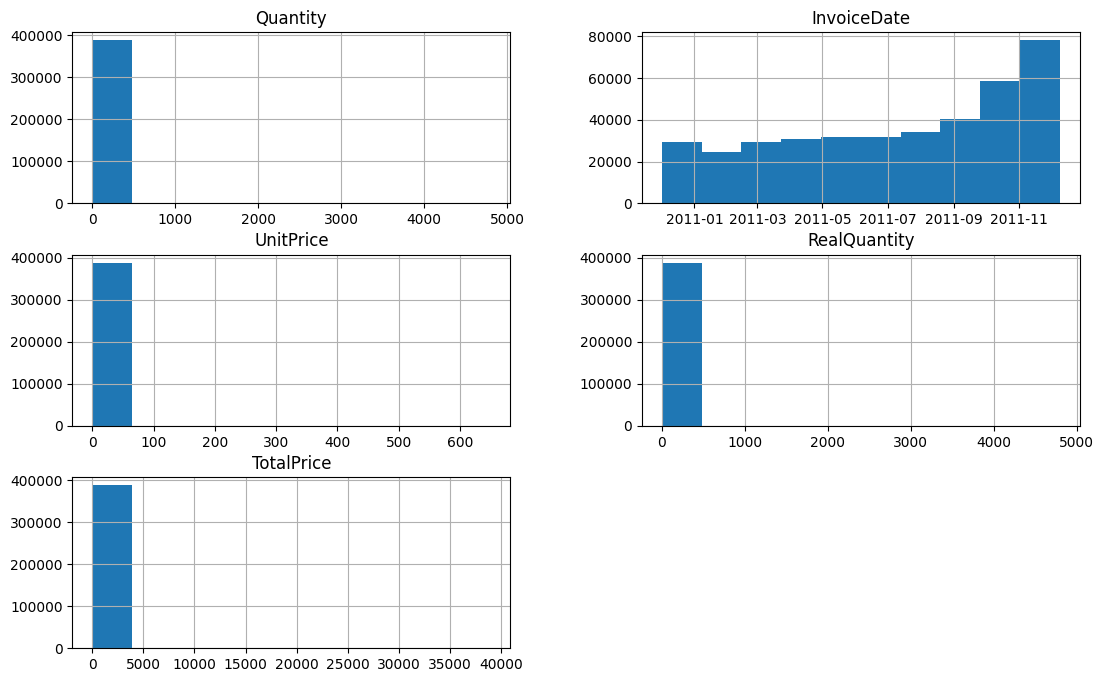

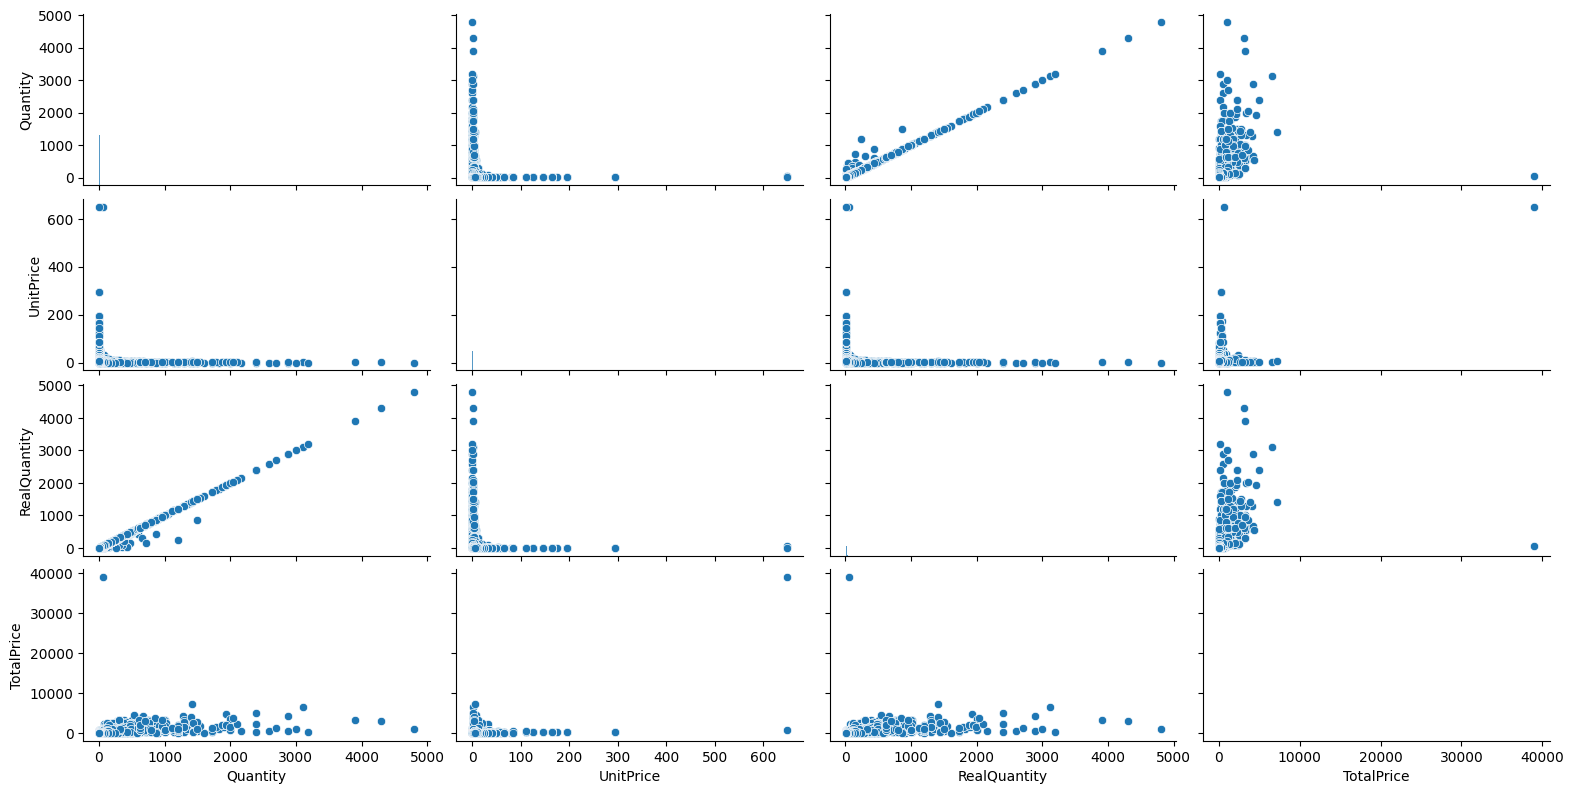

In [2]:
# Выгрузим наши сохраненные очищенные/предобработанные данные
data_cleaned = pd.read_csv('data/data_cleaned.zip', sep=',', dtype={'CustomerID': str,'InvoiceNo': str}, index_col=0, parse_dates=['InvoiceDate'])
# Для вывода основных статистических характеристик для всех признаков воспользуемся методом describe() на предварительно очищенных данных
display(data_cleaned.describe(include='all'))
# Посмотрим предварительно на графики распределения наших числовых признаков
data_cleaned.hist(figsize=(13,8))
sns.pairplot(data=data_cleaned, height=2.0, aspect=2.0, diag_kind = 'hist');

print('Посмотрим на несколько аномальных значений (исключений):')
display(data_cleaned[data_cleaned ['RealQuantity']==4800])
data_cleaned[data_cleaned ['UnitPrice']==649.5]

*Из общего построения попарных взаимосвязей между признаками и основных статистических характеристик можно выделить несколько аспектов:*

- *количество товара в транзакции до 3000 шт., а в основном количества товара по позиции в заказе небольшие. Среднее реальное количество в транзакции приблизительно 13 шт. (если точнее 12.6 шт., но отгружают целым количеством).*
- *цены на продукты не являются дорогими (средняя цена 2,9£). Соответственно и средний чек реальной транзакции примерно 21.4£.*
- *наблюдаются также и аномальные значения (исключения), так называемые выбросы в двух направлениях. Как в направлении количества (в данных есть транзакции с большим количеством), так и направлении цены (имеются и высокие цены на незначительное количество товаров). Следовательно, и в признаке `TotalPrice` полной стоимости продукта в транзакции имееются выбросы. Количество этих аномалий является незначительным.*

Теперь посмотрим детальнее на клиентов из разных стран. Для более лучшего восприятия визуализации построим диаграммы только для клиентов 15 стран, которые составляют рейтинг наибольших продаж. Стоит отметить, что данные по этим 15 странам составляют около 99% от всех данных. Далее будем рассматривать эти страны.

In [364]:
data_country=data_cleaned.groupby(by='Country',as_index=False).agg({'RealQuantity':'sum', 'TotalPrice':'sum','InvoiceNo':lambda x: round(x.shape[0]/data_cleaned.shape[0]*100, 2)}).\
    rename(columns={'InvoiceNo':'Transaction_frequency'})
display(data_country)
# Построим столбчатую диаграмму и линейный график для визуализации распределения реального количества продаж и общей выручки по странам.
diag_barplot = px.bar(data_frame = data_country.nlargest(n=15, columns=['RealQuantity','TotalPrice']),#.sort_values(by=['RealQuantity','TotalPrice'], ascending=False,)[:15] #ignore_index=True),
            x='Country', y='RealQuantity', 
            barmode='stack', color='Country',
            text='RealQuantity', orientation='v',
            title="Распределение реального количества продаж и общей выручки по странам.", 
            #pattern_shape='Country', pattern_shape_sequence=["/", "x", "\\", "+"],
            labels={'RealQuantity':'Реальное количество товаров, шт.', 'Country':'Страны'},
            height =700, width = 1300,)
diag_barplot.update_layout( uniformtext_minsize=10, uniformtext_mode='show', title_xanchor='center', title_x=0.5) # настраиваем подпись на столбцах диаграммы и заголовок диаграммы
diag_barplot.update_layout( legend=dict( font = dict(size= 12), borderwidth=0.5, orientation= 'h', x= 0.5, y= -0.35,  maxheight = 0.1,
                               xanchor= 'center', yanchor= 'bottom')) # настраиваем легенду
#diag_barplot.update_traces(showlegend=False)  #Отключаем легенду
#diag_barplot.update_yaxes(visible=True, showticklabels=False)
diag_barplot.update_traces(width=0.51, textfont_size=13, textposition = "auto", textangle=0, textfont_color='saddlebrown') # настраиваем ширину столбцов диаграммы и подписи на ней
diag_barplot.update_xaxes(side = 'bottom') # место подписи на оси x
diag_barplot.add_trace(px.line(data_frame=data_country.nlargest(n=15, columns=['RealQuantity','TotalPrice']), x='Country', \
    y='TotalPrice', color_discrete_sequence= ['springgreen'], line_shape = 'spline', text='TotalPrice')# line_dash_sequence=['dashdot'])\
    .update_traces(hovertemplate='Объем выручки: %{y} £<br>в стране: %{x}')
    .update_traces(yaxis="y3", name="Объем общей выручки по странам", textfont_color='orangered', textposition = "top right", textfont_size=11).data[0])\
    .update_layout(yaxis3={"overlaying": "y", "side": "right", "title_text":"Значения выручки компании, £"}, showlegend=True,).update_traces(showlegend=True)
diag_barplot.show()

# Добавляем к построенной диаграмме количественную столбчатую диаграмму, чтобы показать соотношения частот позиций заказов/транзакций в каждой из стран (соотношение долей).
diag_barplot_freq = px.bar(data_frame = data_country.nlargest(n=15, columns=['RealQuantity','TotalPrice']),#.sort_values(by=['RealQuantity','TotalPrice'], ascending=False,)[:15] #ignore_index=True),
            x='Country', y='Transaction_frequency', 
            barmode='stack', color='Country',
            text='Transaction_frequency', orientation='v',
            title="Распределение клиентов по частоте транзакций/позиций заказов в каждой из стран.", 
            #pattern_shape='Country', pattern_shape_sequence=["/", "x", "\\", "+"],
            labels={'Transaction_frequency':'Частота транзакций, %', 'Country':'Страны'},
            height =700, width = 1300,)
diag_barplot_freq.update_layout( uniformtext_minsize=10, uniformtext_mode='show', title_xanchor='center', title_x=0.5) # настраиваем подпись на столбцах диаграммы и заголовок диаграммы
diag_barplot_freq.update_layout( legend=dict( font = dict(size= 12), borderwidth=0.5, orientation= 'h', x= 0.5, y= -0.35,  maxheight = 0.1,
                               xanchor= 'center', yanchor= 'bottom')) # настраиваем легенду

,Country,RealQuantity,TotalPrice,Transaction_frequency
0,Australia,83348.0,136950.25,0.29
1,Austria,4838.0,8720.98,0.10
2,Bahrain,260.0,548.40,0.00
3,Belgium,22881.0,36673.04,0.50
4,Brazil,356.0,1143.60,0.01
5,Canada,2762.0,3115.44,0.04
6,Channel Islands,9471.0,19930.64,0.19
7,Cyprus,6295.0,12801.26,0.15
8,Czech Republic,631.0,729.23,0.01
9,Denmark,8147.0,18042.14,0.09


*Из выше построенных диаграмм можно сделать вывод, что лидером по количеству отгруженных товаров, выручке и частоте созданных транзакций является Великобритания причем с огромным отрывом. Следующая группа представителей (Нидерланды, Республика Ирландия и Германия, Франция) в разных рейтингам конкурируют между собой, то есть по количеству отгруженного товара и выручке Нидерланды, Республика Ирландия на 2-м месте, на 3-м Германия, Франция, зато по частоте эти группы меняются местами. Значит во Францию и Германию отгружался более разнообразный товар позиций в заказах больше. Так же можно отметить, что в Швецию и Японию отгружались заказы не очень разнообразные, зато продукты были не самые дешевые.*


Посмотрим на два показателя в наших продажах: на выручку и среднюю выручку в расчёте на одну единицу продукции.

Средняя выручка позволяет оценить типичную величину дохода, сгладить случайные колебания (чтобы в данных исключить другие цикличности, которые присутствуют в течение дня, в течение недели или любые другие) и сравнить разные временные интервалы.

In [ ]:
# Чтобы провести исследования по месяцам, дням неделям и часам, нам нужно создать несколько вспомогательных признаков преобразованных из признака ['InvoiceDate']
data_with_timestamps = data_cleaned.copy()
data_with_timestamps['date'] = data_with_timestamps['InvoiceDate'].dt.date
data_with_timestamps['year'] = data_with_timestamps['InvoiceDate'].dt.year
data_with_timestamps['month'] = data_with_timestamps['InvoiceDate'].dt.month
data_with_timestamps['month_name'] = data_with_timestamps['InvoiceDate'].dt.month_name(locale='ru')
data_with_timestamps['day_of_week'] = data_with_timestamps['InvoiceDate'].dt.day_of_week
#data_with_timestamps['day'] = data_with_timestamps['InvoiceDate'].dt.day # день в месяце
data_with_timestamps['day_name'] = data_with_timestamps['InvoiceDate'].dt.day_name(locale='ru')
data_with_timestamps['hour'] = data_with_timestamps['InvoiceDate'].dt.hour
#data_with_timestamps.info()

# Группируем данные для нахождения общей выручки и выручки, полученной в разных странах, по месяцам  
data_total_revenue = data_with_timestamps.groupby(by=['year','month','month_name'], as_index=False)['TotalPrice'].sum()
#display(data_total_revenue)
data_revenue = data_with_timestamps.groupby(by=['Country','year','month','month_name'], as_index=False)['TotalPrice'].sum()
# Возмем только 15 стран, которые составляют рейтинг наибольших продаж
data_revenue = data_revenue[data_revenue['Country'].isin(data_country.nlargest(n=15, columns=['RealQuantity','TotalPrice'])['Country'].values)]
#display(data_revenue)
# Для объединения вводим признак и заполняем значения общая выручка'Total revenue'
data_total_revenue['Country']= 'Total revenue' 
data_total_revenue = data_total_revenue.iloc[:,[4,0,1,2,3]] # новый порядок признаков
# Собираем data_total_revenue и data_revenue в один датафрейм
data_revenue = data_revenue.merge(right = data_total_revenue, how = 'outer')
display(data_revenue)

# Теперь почти тоже самое произведем для нахождения средней выручки в расчёте на одну единицу продукции по месяцам
#display(data_revenue['Country'].nunique())
# Находим общую среднюю выручку в расчёте на одну единицу продукции и создаем для этого признак['average revenue']
#data_average_revenue_per_month_total = data_with_timestamps.groupby(by=['year','month','month_name'], as_index=False)[['TotalPrice']].mean() # так получается средняя выручка в расчёте на одну единицу позиции заказа/транзакции
data_average_revenue_per_month_total = data_with_timestamps.groupby(by=['year','month','month_name'], as_index=False).agg({'TotalPrice':'sum','RealQuantity':'sum'})
data_average_revenue_per_month_total['average revenue']= data_average_revenue_per_month_total.TotalPrice/data_average_revenue_per_month_total.RealQuantity
#display(data_average_revenue_per_month_total)
# Тоже самое сделаем и для средней выручки для разных стран и создадим такой же признак ['average revenue']
data_average_revenue_per_month = data_with_timestamps.groupby(by=['Country','year','month','month_name'], as_index=False).agg({'TotalPrice':'sum','RealQuantity':'sum'})
data_average_revenue_per_month['average revenue']= data_average_revenue_per_month.TotalPrice/data_average_revenue_per_month.RealQuantity
# Возмем только 15 стран, которые составляют рейтинг наибольших продаж
data_average_revenue_per_month = data_average_revenue_per_month[data_average_revenue_per_month['Country'].isin(data_country.nlargest(n=15, columns=['RealQuantity','TotalPrice'])['Country'].values)]
#display(data_average_revenue_per_month)
# Для объединения вводим признак и заполняем значения общая средняя выручка'Total average revenue'
data_average_revenue_per_month_total['Country']= 'Total average revenue' 
data_average_revenue_per_month_total = data_average_revenue_per_month_total.iloc[:,[6,0,1,2,3,4,5]] # новый порядок признаков
# Собираем data_average_revenue_per_month_total и data_average_revenue_per_month в один датафрейм
data_average_revenue_per_month = data_average_revenue_per_month.merge(right = data_average_revenue_per_month_total, how = 'outer')
display(data_average_revenue_per_month)

# Посмотрим на графики выручки и средней выручки в расчёте на одну единицу продукции каждый месяц
linear_graph_1 = px.line(data_frame=data_revenue, x=list(map(lambda x, y: x+' '+y, list(data_revenue['month_name'].values), list(map(str,data_revenue['year'].values)))), # объединение 2-х признаков для оси x list(zip(list(data_revenue['month_name'].values), list(map(str,data_revenue['year'].values))))
                       y='TotalPrice', color = 'Country', #text='TotalPrice'
                       title='Распределение общей выручки и выручки, полученной в разных странах, по месяцам.',
                       labels ={'x':'Временной период', 'TotalPrice':'Значения выручки компании, £'},
                       line_shape = 'spline', height =800, width = 1300,)
linear_graph_1.show()

linear_graph_2 = px.line(data_frame=data_average_revenue_per_month, x=list(map(lambda x, y: x+' '+y, list(data_average_revenue_per_month['month_name'].values), list(map(str,data_average_revenue_per_month['year'].values)))), # объединение 2-х признаков для оси x list(zip(list(data_average_revenue['month_name'].values), list(map(str,data_average_revenue['year'].values))))
                       y='average revenue', color = 'Country', #text='average revenue'
                       title='Распределение средней выручки в расчёте на одну единицу продукции по месяцам.',
                       labels ={'x':'Временной период', 'average revenue':'Значения средней выручки, £/шт.'},
                       line_shape = 'spline', height =800, width = 1300,)
linear_graph_2.show()

,Country,year,month,month_name,TotalPrice
0,Australia,2010,12,Декабрь,965.35
1,Australia,2011,1,Январь,9017.71
2,Australia,2011,2,Февраль,14141.27
3,Australia,2011,3,Март,17103.29
4,Australia,2011,4,Апрель,421.60
...,...,...,...,...,...
193,United Kingdom,2011,8,Август,479333.54
194,United Kingdom,2011,9,Сентябрь,777252.06
195,United Kingdom,2011,10,Октябрь,784030.58
196,United Kingdom,2011,11,Ноябрь,955931.24


,Country,year,month,month_name,TotalPrice,RealQuantity,average revenue
0,Australia,2010,12,Декабрь,965.35,457.0,2.112363
1,Australia,2011,1,Январь,9017.71,5644.0,1.597752
2,Australia,2011,2,Февраль,14141.27,8535.0,1.656856
3,Australia,2011,3,Март,17103.29,10345.0,1.653290
4,Australia,2011,4,Апрель,421.60,224.0,1.882143
...,...,...,...,...,...,...,...
193,United Kingdom,2011,8,Август,479333.54,303468.0,1.579519
194,United Kingdom,2011,9,Сентябрь,777252.06,448357.0,1.733556
195,United Kingdom,2011,10,Октябрь,784030.58,458016.0,1.711797
196,United Kingdom,2011,11,Ноябрь,955931.24,558032.0,1.713040


*Рассматривая кривые выручки и средней выручки можно констатировать, что поведение общей выручки и средней выручки в расчёте на одну единицу продукции имеет поведение лидера продаж, а основные продажи сделаны в Великобритании. Это можно посмотреть включая и выключая нужные графики в интерактивных легендах plotly.*

*На графике средней выручки в расчёте на одну единицу продукции можно увидеть, что некоторые отгрузки состояли из более дорогих товаров (такие как в Норвегию(Norway)) относительно общей средней выручки (Total average revenue).*

*Для оценки сезонности нужно посмотреть данные за несколько лет по одинаковым месяцам, но у нас другие периоды отсутствуют (есть только два повторяющихся месяца за разные - это декабрь 2010 и декабрь 2011, но и то декабрь 2011 неполный, только до 09.12.2011г). На графике общей выручки можно просто отметить, что возрастающие пики заметны весной в марте, май и июнь (начало лета), а также большой всплеск продаж с августа по ноябрь 2011 года.*

*Для более лучшей оценки продаж рассмотрим динамику так называемого коэффициента сезонности (скорее эффективности, т.е. посмотрим на сколько больше были продажи в месяц относительно средних продаж за рассматриваемый период).*

*Коэффициент сезонности — это числовой показатель, который отражает, насколько объём продаж в конкретный период (месяц, неделю, квартал) отклоняется от среднего уровня из-за сезонных факторов. Он помогает понять закономерности колебаний спроса, связанных с временем года, праздниками, климатическими условиями или другими повторяющимися событиями.*

*Рассмотрим коэффициент сезонности на периоде с полными месяцами в нашем случае это период с декабря 2010 по ноябрь 2011гг.*

In [ ]:
# Группируем данные для нахождения коэффициента сезонности в каждом месяце 
data_total_seasonal_coefficient = data_with_timestamps[data_with_timestamps['InvoiceDate']<='2011-11-30 23:59:59'].\
    groupby(by=['year','month','month_name'], as_index=False).agg({'TotalPrice':'sum','RealQuantity':'sum'})
#display(data_total_seasonal_coefficient)
#data_total_seasonal_coefficient['TotalPrice'].mean()
data_seasonal_coefficient = data_with_timestamps[data_with_timestamps['InvoiceDate']<='2011-11-30 23:59:59'].\
    groupby(by=['Country','year','month','month_name'], as_index=False).agg({'TotalPrice':'sum','RealQuantity':'sum'})
# Возмем только 15 стран, которые составляют рейтинг наибольших продаж
data_seasonal_coefficient = data_seasonal_coefficient[data_seasonal_coefficient['Country'].isin(data_country.nlargest(n=15, columns=['RealQuantity','TotalPrice'])['Country'].values)]
#(data_seasonal_coefficient)
# Для объединения вводим признак и заполняем значения общий коэфициент сезонности 'Total seasonal coefficient'
data_total_seasonal_coefficient['Country']= 'Total seasonal coefficient' 
data_total_seasonal_coefficient = data_total_seasonal_coefficient.iloc[:,[5,0,1,2,3,4]] # новый порядок признаков
# Собираем data_total_seasonal_coefficient и data_seasonal_coefficient  в один датафрейм
data_seasonal_coefficient = data_seasonal_coefficient.merge(right = data_total_seasonal_coefficient, how = 'outer')
#display(data_seasonal_coefficient)
# Далее расчитываем для данных, найденных выше, коэффициент сезонности
for index, col in data_seasonal_coefficient.iterrows():
    #print (col)
    data_seasonal_coefficient.loc[index,'seasonal coefficient'] = col['TotalPrice']/data_seasonal_coefficient[data_seasonal_coefficient['Country']==col['Country']]['TotalPrice'].mean()
display(data_seasonal_coefficient)

# Построим крывые коэффициента сезонности
linear_graph = px.line(data_frame=data_seasonal_coefficient, x=list(map(lambda x, y: x+' '+y, list(data_seasonal_coefficient['month_name'].values), list(map(str,data_seasonal_coefficient['year'].values)))), # объединение 2-х признаков для оси x list(zip(list(data_seasonal_coefficient['month_name'].values), list(map(str,data_seasonal_coefficient['year'].values))))
                       y='seasonal coefficient', color = 'Country', #text='seasonal coefficient'
                       title='Динамика коэффициента сезонности в рассматриваемый период.',
                       labels ={'x':'Временной период', 'seasonal coefficient':'Значения коэффициента сезонности'},
                       line_shape = 'spline', height =800, width = 1300,)
linear_graph.show()

,Country,year,month,month_name,TotalPrice,RealQuantity,seasonal coefficient
0,Australia,2010,12,Декабрь,965.35,457.0,0.084587
1,Australia,2011,1,Январь,9017.71,5644.0,0.790159
2,Australia,2011,2,Февраль,14141.27,8535.0,1.239101
3,Australia,2011,3,Март,17103.29,10345.0,1.498643
4,Australia,2011,4,Апрель,421.60,224.0,0.036942
...,...,...,...,...,...,...,...
180,United Kingdom,2011,7,Июль,475691.69,297462.0,0.874237
181,United Kingdom,2011,8,Август,479333.54,303468.0,0.880930
182,United Kingdom,2011,9,Сентябрь,777252.06,448357.0,1.428452
183,United Kingdom,2011,10,Октябрь,784030.58,458016.0,1.440909


*Как можно заметить по коэффициенту сезонности исходя из всех продаж: высокий сезон начинается чуть позже начала августа значение коэффициента больше 1. Следовательно эффективные продажи (выше среднего за период) начинаются только с августа.*

*Да существуют и продажи в других странах с несколько иным характером, где продажи находятся дольше за границей значения 1 (например, Нидерланды, Австралия и другие), но у них и круче спады в продажах и самих продаж намного меньше лидера. Огромная часть продаж осуществляется в Великобритании, поэтому и поведение коэффициента сезонности всей компании почти одинаково с поведением коэффициента сезонности Великобритании.*

Теперь займемся анализом наиболее загруженных часов в рабочем дне.

In [394]:
# Создадим датафрейм для построения диаграммы распределения количества ежедневно поступающих заказов от времени суток.
data_average_number = data_with_timestamps.groupby(by=['hour'], as_index=False)['InvoiceNo'].nunique()
average_number = data_with_timestamps.groupby(by=['date', 'hour'])['InvoiceNo'].nunique().unstack().fillna(0).mean()
#display(data_with_timestamps.groupby(by=['date', 'hour'])['InvoiceNo'].nunique().unstack().fillna(0).mean().to_frame())
#display(pd.DataFrame(data_with_timestamps.groupby(by=['hour', 'date'], as_index=False)['InvoiceNo'].nunique().pivot_table(index='hour', columns='date', values = 'InvoiceNo', fill_value=0).mean(axis=1)))
data_average_number.loc[:,'average_number']=average_number.values
display(data_average_number)

# Теперь построим диаграмму распределения количества ежедневно поступающих заказов от времени суток и кривую среднего количества ежедневно поступающих заказов
diag_barplot = px.bar(data_frame = data_average_number, x='hour', y='InvoiceNo', 
             barmode='stack', #color='InvoiceNo',
             text='InvoiceNo',
             title="Распределение общего количества и среднего количества поступающих заказов ежедневно в рабочие время суток.", 
             #pattern_shape='hour'.index, pattern_shape_sequence=["/", "x", "\\", "+"],
             labels={'InvoiceNo':'Количество поступающих заказов, шт.', 'hour':'Рабочий период времени, ч.'},
             height =550, width = 1300,)
diag_barplot.update_layout( uniformtext_minsize=3, uniformtext_mode='show', title_xanchor='center', title_x=0.5) # настраиваем подпись на столбцах диаграммы и заголовок диаграммы
diag_barplot.update_layout( legend=dict( font = dict(size= 12), borderwidth=0.5, orientation= 'h', x= 0.5, y= -0.27,  
                               xanchor= 'center', yanchor= 'bottom')) # настраиваем легенду
#fig.update_traces(showlegend=False)  #Отключаем легенду
#fig.update_yaxes(visible=True, showticklabels=False)
diag_barplot.update_traces(width=0.58, textfont_size=13,  textposition = "auto", textangle =0, textfont_color='navy') # настраиваем ширину столбцов диаграммы и подписи на ней
diag_barplot.update_xaxes(side = 'bottom') # место подписи на оси x
diag_barplot.add_trace(px.line(data_frame = data_average_number, x='hour', \
    y='average_number', color_discrete_sequence= ['springgreen'], line_shape = 'spline', text=data_average_number['average_number'].round(2))# line_dash_sequence=['dashdot'])\
    .update_traces(hovertemplate='Среднее количество поступающих заказов ежедневно: %{y}<br>в %{x} ч.')
    .update_traces(yaxis="y3", name="Среднее количество заказов", textfont_color='green', textposition = "top center", textfont_size=12).data[0])\
    .update_layout(yaxis3={"overlaying": "y", "side": "right", "title_text":"Значения среднего количества заказов"}, showlegend=True,)

,hour,InvoiceNo,average_number
0,6,1,0.003279
1,7,29,0.095082
2,8,552,1.809836
3,9,1373,4.501639
4,10,2195,7.196721
5,11,2250,7.377049
6,12,3110,10.196721
7,13,2614,8.570492
8,14,2245,7.360656
9,15,2009,6.586885


*Распределение общего количества и среднего количества ежедневно поступающих заказов в рабочий период времени близко к нормальному распределению, в котором наибольшая активность приходится на период с 10 до 15 с максимальным значением в 12 часов дня.*

Посмотрим на недельное распределение количества заказов (по дням недели).

In [416]:
# Для построения тепловой диаграммы создадим сводную таблицу, по строкам которой отложены часы ('hour'), по столбцам — дни недели ('day_of_week', 'day_name'),
# а на пересечение категорий в ячейках — количество заказов.
pivot_count_hour_day_of_week = data_with_timestamps[['day_of_week','day_name','hour', 'InvoiceNo']].pivot_table(index=['day_of_week','day_name'], columns='hour',\
    values='InvoiceNo', fill_value=0, aggfunc ='nunique')
#display(pivot_count_hour_day_of_week)
# построим тепловую карту, чтобы посмотреть как соотносятся количество ежедневно поступающих заказов в рабочее время в течение недели
fig_hour_day_of_week = px.imshow(pivot_count_hour_day_of_week, x=list(pivot_count_hour_day_of_week.columns), y=list(map(lambda x: x[1],pivot_count_hour_day_of_week.index)),
    height=700,
    width=1000,
    text_auto=True, color_continuous_scale='turbo',
    title="Cоотношение количества ежедневно поступающих заказов по дням недели в рабочее время.",).update_yaxes(title_text='Дни недели')\
    .update_xaxes(title_text='Рабочий период времени, ч.')
    #labels={'hour':[Рабочий период времени, ч.], 'day_of_week':['Дни недели']})
fig_hour_day_of_week.show()

*В соответствии с представленной теплой картой можно отметить некоторые моменты:*
- *Наибольшая суточная активность приходиться на середину недели в среду и в четверг.*
- *В воскресенье самое наименьшее количество заказов.*
- *Суббота является выходным днем (заказы отсутствуют).*

### Построение RFM-таблицы и поиск RFM-выбросов

Cформируем признаки, на основе которых мы будем производить сегментацию клиентов.

Для этого давайте познакомимся с очень популярным методом для анализа потребительской ценности под названием RFM. 

Метод заключается в группировке клиентов на основе следующих параметров:
* Recency (Давность) — давность последней покупки клиента;
* Frequency (Частота) — общее количество покупок клиента;
* Monetary Value (Денежная ценность) — сколько денег потратил клиент.

Суть RFM-анализа состоит в том, что мы разделяем всех клиентов на группы в зависимости от того, как давно они сделали последнюю покупку, как часто покупали и насколько большой была сумма их заказов. 

Мы можем рассчитать RFM-характеристики для каждого из клиентов в нашем датасете и на их основе с помощью методов кластеризации построить подобные сегменты клиентов, привязанные к нашим данным.

Чтобы получить RFM-таблицу, нам необходимо сгруппировать данные по идентификаторам клиента и рассчитать следующие  агрегированные характеристики:

* Recency для i-го клиента рассчитывается как разница между датой и временем последнего заказа и точкой отсчёта, переведённая в дни:
    $$t_0-max(t_{i1}, t_{i2},..., t_{iM})$$

    где $t_{ij}$ — дата и время совершения i-ым клиентом своей j-ой покупки.

    В качестве точки отсчёта $t_0$ берём дату на один день «старше», чем все наши данные. Это будет 10 декабря 2011 года (в формате datetime — '2011-12-10 00:00:00').

* Frequency рассчитывается как общее количество уникальных заказов, которые совершил i-ый клиент.
* Monetary Value рассчитывается как общая сумма денег, которую i-ый клиент потратил на наши товары (с учётом возвратов).

Когда рассчитаем все характеристики, дадим столбцам результирующей таблицы соответствующие названия.

In [230]:
# Назначаем точку отчета,берём дату на один день «старше», чем рассматриваемый период в наших данных.
t_0 = pd.to_datetime('2011-12-10 00:00:00')
# Собираем RFM - характеристики для каждого клиента в отдельный датафрейм (RFM-таблицу).
rfm_table = data_cleaned.groupby(by='CustomerID', as_index=True).agg({'InvoiceDate':lambda x: (t_0-x.max()).days, # Recency
                                                                       'InvoiceNo':'nunique',# Frequency
                                                                       'RealQuantity':'sum'} # Monetary
                        ).rename(columns={'InvoiceDate':'Recency','InvoiceNo':'Frequency','RealQuantity':'Monetary'})
rfm_table

,Recency,Frequency,Monetary
CustomerID,,,
12347,2,7,2458.0
12348,75,4,2332.0
12349,18,1,630.0
12350,310,1,196.0
12352,36,7,463.0
...,...,...,...
18280,277,1,45.0
18281,180,1,54.0
18282,7,2,98.0


После того как подготовили RFM-таблицу, визуализируем каждую из трёх компонент, например, в виде коробчатых диаграмм (boxplot).

In [231]:
from plotly.subplots import make_subplots # Для создания матрицы из нескольких систем координат
# Строим коробчатые диаграммы для RFM - характеристик. Создадим для этого функцию.
def create_box_diagram (data):
    boxes = [px.box(data, x=column) for column in data.columns]
    fig = make_subplots(rows=1, cols=len(data.columns), subplot_titles=("Recency","Frequency", "Monetary"))
# Размещаем все графики в одну строку
    for i, box in enumerate(boxes):
        fig.add_trace(boxes[i]['data'][0], row=1, col=i+1)
        fig.update_layout(showlegend=True)
        #fig.write_html('plotly/boxplot_1.html')
    return fig.show()

create_box_diagram(rfm_table)

*Есть клиенты с аномально большим количеством сделанных заказов (более 100 штук), а также клиенты, общая стоимость заказов которых превышает 190 тысяч фунтов стерлингов.*

Выбросы могут отрицательно сказаться на результатах работы методов кластеризации, неустойчивых к ним, например алгоритма KMeans, поэтому хотелось бы от них избавиться. Однако терять много ценных данных о клиентах тоже не хочется, поэтому ограничимся верхней границей соответствующей квантили уровня 0.95. Таким образом, мы удалим данные тех клиентов, для которых значение параметра Frequency или параметра Monetary выше, чем у 95 % клиентов.

In [232]:
#rfm_table.Frequency.quantile(q=0.95)
#rfm_table.Monetary.quantile(q=0.95)
mask = (rfm_table['Frequency']<=rfm_table.Frequency.quantile(q=0.95))&(rfm_table['Monetary']<=rfm_table.Monetary.quantile(q=0.95))
rfm_table = rfm_table[mask]
#rfm_table
# Посмотрим как изменились распределения в наших данные на коробчатых диаграммах.
create_box_diagram(rfm_table)

## 3. Моделирование и оценка качества моделей.

Посмотрим как наши RFM - характеристики упорядочены в пространстве. Визуализируем их.

In [233]:
#display(rfm_table)
fig = px.scatter_3d(data_frame=rfm_table, 
    x = 'Recency', y = 'Frequency', z = 'Monetary', 
    title= 'Расположение рассматриваемых данных в пространстве RFM',width=1100, height=800)
fig.show()

*В данных не очень заметны какие-либо однородные скопления с высокой плотностью. Более менее рядная упорядоченность можно увидеть по оси Частоты(Frequency). Наибольшее скопление данных стоимостью (Monetary) до 2000£ и давность (Recency) до 200 дней.*

Так же взглянем на сколько зависимы между собой наши RFM-характеристики (на корреляцию признаков).

In [234]:
# построим тепловую карту, на которой отобразим матрицу корреляции
fig = px.imshow(rfm_table.corr(method='pearson').round(2), x=list(rfm_table.columns), y=list(rfm_table.columns),
    height=500,
    width=800,
    text_auto=True, color_continuous_scale='turbo',
    title="Корреляционная матрица RFM-характеристик", ) 
fig.show()

*Между характеристиками RFМ существуют зависимости, слабые (Monetary-Recency(обратная -0.36)) и средние корреляционные связи (Frequency-Recency(обратная -0.41), Monetary-Frequency(прямая 0.69)). В связи с этим имеет смысл преобразовать данные таким образом, чтобы они перестали зависеть друг от друга, т.е. представим их в новой системе координат/в новом базисе, или можно сказать спроецируем данные в пространство 3-х главных компонент не сжимая его (без снижения размерности) с помощью  сингулярного разложения (SVD - Singular Value Decomposition) или  метода главных компонент (PCA - Principal Component Analysis) при условии линейных зависимостей в данных.*

*А можно попробовать преобразовать данные нелинейным методом снижения размерности и разделения данных - стохастическим вложением соседей с t-распределением (t-SNE - t‑Distributed Stochastic Neighbor Embedding, который в первую очередь используют для визуализации высокоразмерных данных).*

In [235]:
# Для небольшого сокращения кода и удобства обернем шаги по предобработке данных в pipeline.
# В pipeline данные стандартизируем (можно и нормализовать), т.е. приводим данные к одной шкале(масштабу). Это также нужно, чтобы методы понижения размерности работали стабильно.
pipeline_svd = pipeline.Pipeline([('scaler', preprocessing.StandardScaler()), ('svd', TruncatedSVD(n_components=3))]) # PCA в нашем случае одно и тоже
#pipeline_pca = pipeline.Pipeline([('scaler', preprocessing.StandardScaler()), ('pca', PCA(n_components=0.9))])
pipeline_svd.fit(rfm_table)
#pipeline_pca.fit(rfm_table)
rfm_table_svd = pd.DataFrame(pipeline_svd.transform(rfm_table), columns=['SVD_0', 'SVD_1','SVD_2'])
#rfm_table_pca = pd.DataFrame(pipeline_pca.transform(rfm_table), columns=['PCA_0', 'PCA_1','PCA_2'])
#display(rfm_table_pca.round(2)==rfm_table_svd.round(2))
#rfm_table_svd
pipeline_tsne = pipeline.Pipeline([('scaler', preprocessing.StandardScaler()), ('tsne', TSNE(n_components=3, perplexity=50, random_state=42))])
rfm_table_tsne =  pd.DataFrame(pipeline_tsne.fit_transform(rfm_table), columns=['TSNE_0', 'TSNE_1','TSNE_2'])

c:\Users\Хозяин\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\manifold\_t_sne.py:800: FutureWarning:

The default initialization in TSNE will change from 'random' to 'pca' in 1.2.

c:\Users\Хозяин\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\manifold\_t_sne.py:810: FutureWarning:

The default learning rate in TSNE will change from 200.0 to 'auto' in 1.2.



In [238]:
# Посмотрим  на преобразованные данные
fig_1 = px.scatter_3d(data_frame=rfm_table_svd, 
    x ='SVD_0', y ='SVD_1', z ='SVD_2', #title= 'Расположение преобразованных данных в новом пространстве',
    width=1300, height=800)
fig_2 = px.scatter_3d(data_frame=rfm_table_tsne, 
    x ='TSNE_0', y ='TSNE_1', z ='TSNE_2', #title= 'Расположение преобразованных данных в новом пространстве',
    width=1300, height=800)
fig = make_subplots(rows=1, cols=2,figure= fig_1, #subplot_titles=("Расположение преобразованных данных в новых пространствах (в пространстве svd и tsne)"),
            specs=[[{'type': 'surface'}, {'type': 'scene'}]])
fig.add_traces(fig_2.data,  rows=1, cols=2)
fig.update_layout(title_text="Расположение преобразованных данных в новых пространствах (в пространстве SVD и TSNE)", title_font_size=24, title_xanchor='center', title_x=0.5)
#fig.update_xaxes(title_text='TSNE_0', col=2).update_yaxes(title_text='TSNE_1', col=2).update_zaxes(title_text='TSNE_2', col=2)
fig.show()


*Видно, что в пространстве SVD данные развернулись относительно новых осей. А вот в пространстве TSNE они ещё и сжались к областям вероятной близости/похожести (каждый к своей).*

Попробуем в самом начале построить кластеризацию воспользовавшись алгоритмом DBSCAN.

In [10]:
# Импортируем DBSCAN-кластеризацию
from sklearn.cluster import DBSCAN
# запускаем кластеризацию на наших данных только сразу увеличим значение eps (расстояние, определяющее окрестности)
# и min_samples (минимальное количество точек в данных, которое может быть в кластере) от заданных по умолчанию
clusters_DBSCAN = DBSCAN(eps=4.8, min_samples=8).fit_predict(rfm_table) # сразу будет вычислять признак с предсказаниями кластеров на первоначальных данных
clusters_DBSCAN_svd = DBSCAN(eps=0.07, min_samples=17).fit_predict(rfm_table_svd) # на преобразованных на SVD
clusters_DBSCAN_tsne = DBSCAN(eps=0.04, min_samples=3).fit_predict(rfm_table_tsne) # на преобразованных на TSNE
#display(np.unique(clusters_DBSCAN))
#display(np.unique(clusters_DBSCAN_svd))
#display(np.unique(clusters_DBSCAN_tsne))

# Посмотрим  разбиение на кластеры алгоритмом DBSCAN
fig_1 = px.scatter_3d(data_frame=rfm_table, 
    x = 'Recency', y = 'Frequency', z = 'Monetary', color = clusters_DBSCAN,
    width=1300, height=800)
fig_2 = px.scatter_3d(data_frame=rfm_table_svd, 
    x ='SVD_0', y ='SVD_1', z ='SVD_2',color = clusters_DBSCAN_svd,
    width=1300, height=800)
fig = make_subplots(rows=1, cols=2,figure= fig_1, #subplot_titles=("Расположение преобразованных данных в новых пространствах (в пространстве svd и tsne)"),
            specs=[[{'type': 'surface'}, {'type': 'scene'}]])
fig.add_traces(fig_2.data,  rows=1, cols=2)
fig.update_layout(title_text="Кластеры, найденные DBSCAN на первоначальных и преобразованных данных (в пространстве SVD) ", title_font_size=21, title_xanchor='center', title_x=0.5)
#fig.update_xaxes(title_text='TSNE_0', col=2).update_yaxes(title_text='TSNE_1', col=2).update_zaxes(title_text='TSNE_2', col=2)
fig.show()

*Выполнив немало разных комбинаций с DBSCAN путем многократного перебора (опытным путем) eps и min_samples как для первоначальных данных, так и для преобразованных данных, можно заметить, что результаты алгоритма неудовлетворительны. Это происходит из-за того, что данные неоднородны: в некоторых областях они имеют высокую плотность, а в других - они разрежены. Приходим к выводу, что данный способ, основанный на плотности, не очень подходит для решения данной задачи (для кластеризации).*

Далее посмотрим как справится спектральная кластеризация с нашей задачей. Данный тип кластеризации использует собственные значения (спектр) матрицы сходства данных, т.е. мы можем задавать не преобразованные данные, а исходные, а все математические преобразование по снижению размерности и матрице сходства происходят внутри этого метода. Но всё же первоначальные данные нормализуем (приведем к одному масштабу).

И ещё будем производить кластеризацию перебирая количество кластеров от 3 до 10 включительно. Это в принципе логично, так как у нас 3 оси (характеристики). Умножая на хотя бы 3 возможных варианта (min, medium, max для каждой характеристики), мы будем иметь от 3-х до 9-и различных ситуации/сценария (кластера), как поведут себя различные клиенты, поэтому то большее или меньшее количество кластеров будет нерелевантно для маркетинга.

Оценку кластеризации будем проводить по внутренним метрикам коэффициенту силуэта, индекс Калински — Харабаса и Индекс Дэвиса — Болдина, которые заложены в библиотеке sklearn. Выбор лучшей модели будем проводить на основании наибольшего значения коэффициентом силуэта.

In [239]:
# Инициализируем нормализатор MinMaxScaler (создаем объект MinMaxScaler для нормализации)
mm_scaler = preprocessing.MinMaxScaler()
# Вычисляем параметры для нормализации стандартизации для каждого столбца и производим преобразование сразу для всех данных
# Обучаем нормализатор и сразу вычисляем на всей выборки data_bank
rfm_table_mm_scaler = mm_scaler.fit_transform(rfm_table)
# Преобразуем промежуточный датасет в полноценный датафрейм
rfm_table_mm_scaler = pd.DataFrame(rfm_table_mm_scaler, columns=rfm_table.columns)
# Создадим пустой датафрейм для занесения результатов исследования всех используемых алгоритмов на наших данных
result_data = pd.DataFrame(columns = ['name_algorithm', 'nuber_clusters', 'coef_silhouette', 'calinski_harabasz_score', 'davies_bouldin_score'])
for num_clusters in range(3,11):
# инициализируем алгоритм кластеризации и сразу обучаем
    spectral_clustering = SpectralClustering(n_clusters=num_clusters, random_state=42).fit(rfm_table_mm_scaler)
    result_data.loc[len(result_data)]= ['Spectral Clustering with MinMaxScaler', num_clusters, \
                                        silhouette_score(rfm_table_mm_scaler, spectral_clustering.labels_),\
                                        calinski_harabasz_score(rfm_table_mm_scaler, spectral_clustering.labels_),\
                                        davies_bouldin_score(rfm_table_mm_scaler, spectral_clustering.labels_)]
# Находим наилучший алгоритм по наибольшему коэффициенту силуэта 
#result_data.groupby(by='name_algorithm', as_index=False).agg({'coef_silhouette':'max'})
max_result_data = result_data[result_data['coef_silhouette']==result_data['coef_silhouette'].max()]
display(max_result_data)
# Теперь данные разделим на то количество кластеров, которое получилось в лучшем алгоритме
clasters = SpectralClustering(n_clusters=max_result_data['nuber_clusters'].values[0], random_state=42).fit_predict(rfm_table_mm_scaler)

# Посмотрим разбиение на кластеры алгоритмом SpectralClustering
fig = px.scatter_3d(data_frame=rfm_table_mm_scaler, 
    x = 'Recency', y = 'Frequency', z = 'Monetary', color = clasters,
    title= 'Кластеры, найденные Spectral Clustering with MinMaxScaler',width=1100, height=800)
fig.show()

,name_algorithm,nuber_clusters,coef_silhouette,calinski_harabasz_score,davies_bouldin_score
0,Spectral Clustering with MinMaxScaler,3,0.490396,4365.721008,0.717501


*Спектральная кластеризация уже показала более лучшие результаты. Продолжим дальнейшее исследование разделения данных на кластеры.*

Далее проведем сегментацию на преобразованных данных в новых пространствах SVD и TSNE с помощью алгоритмов k-means, EM-кластеризация (модель гауссовой смеси), иерархической кластеризации (агломеративный метод), спектральной кластеризации (но уже на преобразованных данных) и также выберем лучшие алгоритмы по наибольшему значению коэффициента силуэта.

In [240]:
# Создадим пустой датафрейм для занесения результатов исследования всех используемых алгоритмов на наших данных в SVD пространстве
result_data_svd = pd.DataFrame(columns = ['name_algorithm', 'nuber_clusters', 'coef_silhouette', 'calinski_harabasz_score', 'davies_bouldin_score'])
# Для алгоритма KMeans
for num_clusters in range(3,11):
# инициализируем алгоритм кластеризации, сразу обучаем и предсказываем кластеры
    k_means_on_svd = KMeans(n_clusters=num_clusters, random_state=42, init='k-means++').fit_predict(rfm_table_svd)
    result_data_svd.loc[len(result_data_svd)]= ['K-means on svd', num_clusters, \
                                        silhouette_score(rfm_table_svd, k_means_on_svd),\
                                        calinski_harabasz_score(rfm_table_svd, k_means_on_svd),\
                                        davies_bouldin_score(rfm_table_svd, k_means_on_svd)]
# Для алгоритма Expectation-maximization(EM)
for num_clusters in range(3,11):
# инициализируем алгоритм кластеризации, сразу обучаем и предсказываем кластеры
    gm_clustering_on_svd = GaussianMixture(n_components=num_clusters, random_state=42).fit_predict(rfm_table_svd)
    result_data_svd.loc[len(result_data_svd)]= ['Gaussian Mixture Model (GMM) on svd', num_clusters, \
                                        silhouette_score(rfm_table_svd, gm_clustering_on_svd),\
                                        calinski_harabasz_score(rfm_table_svd, gm_clustering_on_svd),\
                                        davies_bouldin_score(rfm_table_svd, gm_clustering_on_svd)]
# Для алгоритма AgglomerativeClustering
for num_clusters in range(3,11):
# инициализируем алгоритм кластеризации, сразу обучаем и предсказываем кластеры
    agglomerative_clustering_on_svd = AgglomerativeClustering(n_clusters=num_clusters, linkage='ward').fit_predict(rfm_table_svd)
    result_data_svd.loc[len(result_data_svd)]= ['AgglomerativeClustering on svd', num_clusters, \
                                        silhouette_score(rfm_table_svd, agglomerative_clustering_on_svd),\
                                        calinski_harabasz_score(rfm_table_svd, agglomerative_clustering_on_svd),\
                                        davies_bouldin_score(rfm_table_svd, agglomerative_clustering_on_svd)]
# Для алгоритма SpectralClustering
for num_clusters in range(3,11):
# инициализируем алгоритм кластеризации, сразу обучаем и предсказываем кластеры
    spectral_clustering_on_svd = SpectralClustering(n_clusters=num_clusters, random_state=42).fit_predict(rfm_table_svd)
    result_data_svd.loc[len(result_data_svd)]= ['Spectral Clustering on svd', num_clusters, \
                                        silhouette_score(rfm_table_svd, spectral_clustering_on_svd),\
                                        calinski_harabasz_score(rfm_table_svd, spectral_clustering_on_svd),\
                                        davies_bouldin_score(rfm_table_svd, spectral_clustering_on_svd)]
# display(result_data_svd)

# Находим наилучшие алгоритмы по наибольшему коэффициенту силуэта
max_result_data_svd =  result_data_svd.drop(index=result_data_svd.index) 
for elem in set(result_data_svd['name_algorithm']):
    gr=result_data_svd[result_data_svd['name_algorithm']==elem]
    max_result_data_svd = pd.concat([max_result_data_svd,gr[gr['coef_silhouette']==gr['coef_silhouette'].max()]]).sort_values(by='coef_silhouette', ascending=False)
display(max_result_data_svd)

# Теперь данные разделим на то количество кластеров, которое получилось в лучших алгоритмах K-means и Gaussian Mixture Model(GMM разбил на 5 кластеров)  
clasters_gm_svd = GaussianMixture(n_components=max_result_data_svd['nuber_clusters'].values[3], random_state=42).fit_predict(rfm_table_svd)
clasters_k_means_svd = KMeans(n_clusters=max_result_data_svd['nuber_clusters'].values[0], random_state=42, init='k-means++').fit_predict(rfm_table_svd)

,name_algorithm,nuber_clusters,coef_silhouette,calinski_harabasz_score,davies_bouldin_score
0,K-means on svd,3,0.467976,4248.163182,0.767986
24,Spectral Clustering on svd,3,0.457751,1208.802076,1.084775
16,AgglomerativeClustering on svd,3,0.393188,3072.101125,0.862807
10,Gaussian Mixture Model (GMM) on svd,5,0.254546,2017.397649,1.353059


In [241]:
# Посмотрим разбиение на кластеры алгоритмами K-means и Gaussian Mixture Model(GMM) в пространстве SVD
# Посмотрим  разбиение на кластеры алгоритмом DBSCAN
fig_1 = px.scatter_3d(data_frame=rfm_table_svd, 
    x ='SVD_0', y ='SVD_1', z ='SVD_2', color = clasters_k_means_svd,
    width=1300, height=800)
fig_2 = px.scatter_3d(data_frame=rfm_table_svd, 
    x ='SVD_0', y ='SVD_1', z ='SVD_2',color = clasters_gm_svd,
    width=1300, height=800)
fig = make_subplots(rows=1, cols=2,figure= fig_1, 
            subplot_titles=("Кластеры, найденные K-means в пространсте SVD", "Кластеры, найденные Gaussian Mixture Model в пространсте SVD"),
            specs=[[{'type': 'surface'}, {'type': 'scene'}]])
fig.add_traces(fig_2.data,  rows=1, cols=2)

#fig.update_xaxes(title_text='TSNE_0', col=2).update_yaxes(title_text='TSNE_1', col=2).update_zaxes(title_text='TSNE_2', col=2)
fig.show()

*Можно отметить, что хотя и модель гауссовой смеси не является самой лучшей по коэффициенту силуэта. Её предложенная сегментация является более разнообразным.*
Теперь продолжим кластеризацию на преобразованных данных в пространстве TSNE.

In [242]:
# Создадим пустой датафрейм для занесения результатов исследования всех используемых алгоритмов на наших данных в TSNE пространстве
result_data_tsne = pd.DataFrame(columns = ['name_algorithm', 'nuber_clusters', 'coef_silhouette', 'calinski_harabasz_score', 'davies_bouldin_score'])
# Для алгоритма KMeans
for num_clusters in range(3,11):
# инициализируем алгоритм кластеризации, сразу обучаем и предсказываем кластеры
    k_means_on_tsne = KMeans(n_clusters=num_clusters, random_state=42, init='k-means++').fit_predict(rfm_table_tsne)
    result_data_tsne.loc[len(result_data_tsne)]= ['K-means on tsne', num_clusters, \
                                        silhouette_score(rfm_table_tsne, k_means_on_tsne),\
                                        calinski_harabasz_score(rfm_table_tsne, k_means_on_tsne),\
                                        davies_bouldin_score(rfm_table_tsne, k_means_on_tsne)]
# Для алгоритма Expectation-maximization(EM)
for num_clusters in range(3,11):
# инициализируем алгоритм кластеризации, сразу обучаем и предсказываем кластеры
    gm_clustering_on_tsne = GaussianMixture(n_components=num_clusters, random_state=42).fit_predict(rfm_table_tsne)
    result_data_tsne.loc[len(result_data_tsne)]= ['Gaussian Mixture Model (GMM) on tsne', num_clusters, \
                                        silhouette_score(rfm_table_tsne, gm_clustering_on_tsne),\
                                        calinski_harabasz_score(rfm_table_tsne, gm_clustering_on_tsne),\
                                        davies_bouldin_score(rfm_table_tsne, gm_clustering_on_tsne)]
# Для алгоритма AgglomerativeClustering
for num_clusters in range(3,11):
# инициализируем алгоритм кластеризации, сразу обучаем и предсказываем кластеры
    agglomerative_clustering_on_tsne = AgglomerativeClustering(n_clusters=num_clusters, linkage='ward').fit_predict(rfm_table_tsne)
    result_data_tsne.loc[len(result_data_tsne)]= ['AgglomerativeClustering on tsne', num_clusters, \
                                        silhouette_score(rfm_table_tsne, agglomerative_clustering_on_tsne),\
                                        calinski_harabasz_score(rfm_table_tsne, agglomerative_clustering_on_tsne),\
                                        davies_bouldin_score(rfm_table_tsne, agglomerative_clustering_on_tsne)]
# Для алгоритма SpectralClustering
for num_clusters in range(3,11):
# инициализируем алгоритм кластеризации, сразу обучаем и предсказываем кластеры
    spectral_clustering_on_tsne = SpectralClustering(n_clusters=num_clusters, random_state=42).fit_predict(rfm_table_tsne)
    result_data_tsne.loc[len(result_data_tsne)]= ['Spectral Clustering on tsne', num_clusters, \
                                        silhouette_score(rfm_table_tsne, spectral_clustering_on_tsne),\
                                        calinski_harabasz_score(rfm_table_tsne, spectral_clustering_on_tsne),\
                                        davies_bouldin_score(rfm_table_tsne, spectral_clustering_on_tsne)]
# display(result_data_tsne)

# Находим наилучшие алгоритмы по наибольшему коэффициенту силуэта
max_result_data_tsne =  result_data_tsne.drop(index=result_data_tsne.index) 
for elem in set(result_data_tsne['name_algorithm']):
    gr=result_data_tsne[result_data_tsne['name_algorithm']==elem]
    max_result_data_tsne = pd.concat([max_result_data_tsne,gr[gr['coef_silhouette']==gr['coef_silhouette'].max()]]).sort_values(by='coef_silhouette', ascending=False)
display(max_result_data_tsne)    

# Теперь данные разделим на то количество кластеров, которое получилось в лучших алгоритмах K-means(разбил на 9 кластеров)) и Spectral Clustering(разбил на 6 кластеров)  
clasters_sp_cl_tsne = SpectralClustering(n_clusters=max_result_data_tsne['nuber_clusters'].values[2], random_state=42).fit_predict(rfm_table_tsne)
clasters_k_means_tsne = KMeans(n_clusters=max_result_data_tsne['nuber_clusters'].values[0], random_state=42, init='k-means++').fit_predict(rfm_table_tsne)

,name_algorithm,nuber_clusters,coef_silhouette,calinski_harabasz_score,davies_bouldin_score
6,K-means on tsne,9,0.408956,2802.596178,0.863818
14,Gaussian Mixture Model (GMM) on tsne,9,0.385362,2376.053584,0.860973
27,Spectral Clustering on tsne,6,0.379999,2238.797642,0.893017
17,AgglomerativeClustering on tsne,4,0.365495,2175.654616,0.972508


In [243]:
# Посмотрим разбиение на кластеры алгоритмами K-means и Spectral Clustering в пространстве TSNE
# Посмотрим  разбиение на кластеры алгоритмом DBSCAN
fig_1 = px.scatter_3d(data_frame=rfm_table_tsne, 
   x ='TSNE_0', y ='TSNE_1', z ='TSNE_2', color = clasters_k_means_tsne,
    width=1300, height=800)
fig_2 = px.scatter_3d(data_frame=rfm_table_tsne, 
    x ='TSNE_0', y ='TSNE_1', z ='TSNE_2',color = clasters_sp_cl_tsne,
    width=1300, height=800)
fig = make_subplots(rows=1, cols=2,figure= fig_1, 
            subplot_titles=("Кластеры, найденные K-means в пространсте TSNE", "Кластеры, найденные SpectralClustering в пространсте TSNE"),
            specs=[[{'type': 'surface'}, {'type': 'scene'}]])
fig.add_traces(fig_2.data,  rows=1, cols=2)

#fig.update_xaxes(title_text='TSNE_0', col=2).update_yaxes(title_text='TSNE_1', col=2).update_zaxes(title_text='TSNE_2', col=2)
fig.show()

*Исходя из приведенных диаграмм, можно констатировать, что предложенная кластеризация алгоритмом K-means в пространстве TSNE не только имеет значительный показатель коэффициента силуэта, но и является наиболее показательной сегментацией. Здесь представлен центральный кластер и на каждом крыле этой странной фигуры свой кластер. Вот это так называемая снежинка с видоизмененными лапками (в виде изогнутых закрученных крыльев) показывает изменения во всех направлениях в пространтве (в этом случае TSNE).*

Теперь вернемся в наше пространство (Recency-Frequency-Monetary) и эти найденные кластеры присвоим к исходным данным.

In [271]:
rfm_table_cl = rfm_table.copy()
rfm_table_cl['Clusters']= clasters_k_means_tsne
rfm_table_cl = rfm_table_cl.astype(dtype ={'Clusters':'object'}).sort_values(by='Clusters', ascending=True)
# Посмотрим как найденные кластеры разделят исходные данные 
fig = px.scatter_3d(data_frame=rfm_table_cl, 
    x = 'Recency', y = 'Frequency', z = 'Monetary', color ='Clusters',
    title= 'Распределение кластеров, найденных алгоритмом K-means в TSNE, в исходном пространстве (Recency-Frequency-Monetary)',width=1300, height=800)
fig.show()

*Проведя кластеризацию, можем выделить несколько алгоритмов с наиболее значимыми значениями коэффициента силуэта и разными по количеству кластеров: это алгоритм SpectralClustering с нормированными исходными данными с помощью MinMaxScaler (значение коэффициента силуэта 0.490396, алгоритм разбивает данные на 3 кластера) и алгоритм K-means с преобразованными данными в пространстве TSNE (значение коэффициента силуэта 0.408956, алгоритм разбивает данные на 9 кластеров).*

*Если нам нужно сегментировать данные просто для общего понимания (т.е. для констатации факта, что у нас есть такие клиенты), то нам достаточно 3 кластера (т.е. алгоритм "Spectral Clustering with MinMaxScaler"):*
- *2-ой кластер соответствует «лояльным» клиентам, которые приносят наибольший доход, совершают покупки чаще всего, а давность их последней покупки наименьшая (желтый кластер на соответствующей диаграмме).*
- *0-ой кластер соответствует «промежуточным» клиентам, которые являются активными, но покупают не так часто и много, как лояльные клиенты. В то же время эти клиенты не являются «потерянными» (синий клатер).*
- *1-ый кластер соответствует «потерянным» клиентам, которые купили меньше всего товара, и их последняя покупка была совершена очень давно (пурно-розовый кластер).*

*Если же нам нужно более информативную и подробную сегментацию с точки зрения дальнейших стратегических решений по развитию продаж, чтобы привлечь определенных клиентов с конкретными характеристиками путем специализированных целевых маркетинговых акций, то нужно воспользоваться алгоритмом  K-means в пространсте TSNE, чтобы получить 9 кластеров с более расширенными характеристиками клиента.  Вследствие этого дальнейшую работу по интерпритации результатов будем проводит на 9 кластерах, полученных алгоритмом "K-means on tsne".*

## 4. Анализ и интерпретация результатов кластеризации

В первую очередь посмотрим сколько клиентов приходится в каждом кластере (количественная и процентная оценка).

In [283]:
# Для этого сгруппируем наши данные по кластерам
sunburst_rfm_table_cl = rfm_table_cl.groupby(by=['Clusters'], as_index=False)['Clusters'].value_counts()
sunburst_rfm_table_cl['percent'] =round(sunburst_rfm_table_cl['count']/(sunburst_rfm_table_cl['count'].sum())*100, 2)
display(sunburst_rfm_table_cl)
sunburst = px.sunburst(data_frame=sunburst_rfm_table_cl, path=['Clusters'], values='percent',
                       width=1200, height=700, title="Соотношение клиентов разным кластерам.")
sunburst.show()

,Clusters,count,percent
0,0,387,9.61
1,1,353,8.77
2,2,394,9.79
3,3,530,13.16
4,4,526,13.07
5,5,454,11.28
6,6,434,10.78
7,7,617,15.33
8,8,331,8.22


*Заметно что в кластерах есть небольшой дисбаланс, можно сказать разбиение в кластерах приблизительно равно. Немного выделяются некоторые кластеры по количеству: 7, 3, 4, 5.*

Продолжим наш анализ результатов кластеризации составлением так называемого профиля кластеров. Для этого нам необходимо вернуться от декомпозированных данных (если производили понижение размерности) к RFM-таблице (очищенной от выбросов).

Сгруппируем RFM-таблицу по полученным кластерам и рассчитайте среднее по каждому из признаков.

Чтобы результаты было проще интерпретировать, давайте познакомимся с одним из способов визуализации профиля кластеров — **Radar Chart** (полярная диаграмма, или диаграмма паутины). Это графическое представление значений нескольких эквивалентных категорий в форме паутины.

Radar Chart часто используется при определении профиля кластеров. На концах паутины откладываются оси, соответствующие признакам, описывающим объекты. На каждой из осей для каждого кластера откладываются средние значения соответствующих характеристик. Соединив точки по осям, мы получаем многоугольник. 

В модуле `graph_objects` библиотеки `plotly` есть встроенная функция `Scatterpolar`, которая позволяет построить полярную диаграмму. На основе этой функции была подготовлена функцию `plot_cluster_profile()`, которая позволяет визуализировать профиль каждого из кластеров в виде полярной диаграммы. У неё есть два параметра: `grouped_data` — сгруппированные по кластерам характеристики объектов (клиентов), `n_clusters` — количество кластеров.

Главное условие использования полярной диаграммы — все признаки должны быть приведены к единому масштабу с помощью нормализации, где 1 будет означать максимум, а 0 — минимум (т.е. `MinMaxScaler`). Шаг с нормализацией также добавлен в функцию `plot_cluster_profile()`.

In [286]:
def plot_cluster_profile(grouped_data, n_clusters):
    """Функция для визуализации профиля кластеров в виде полярной диаграммы.

    Args:
        grouped_data (DataFrame): таблица, сгруппированная по номерам кластеров с агрегированными характеристиками объектов.
        n_clusters (int): количество кластеров
    """
    # Нормализуем сгруппированные данные, приводя их к масштабу 0-1.
    scaler = preprocessing.MinMaxScaler()
    grouped_data = pd.DataFrame(scaler.fit_transform(grouped_data), columns=grouped_data.columns)
    # Создаём список признаков
    features = grouped_data.columns
    # Создаём пустую фигуру
    fig = go.Figure()
    # В цикле визуализируем полярную диаграмму для каждого кластера
    for i in range(n_clusters):
        # Создаём полярную диаграмму и добавляем её на общий график
        fig.add_trace(go.Scatterpolar(
            r=grouped_data.iloc[i].values, # радиусы
            theta=features, # название засечек
            fill='toself', # заливка многоугольника цветом
            name=f'Cluster {i}', # название — номер кластера
        ))
    # Обновляем параметры фигуры
    fig.update_layout(
        showlegend=True, # отображение легенды
        autosize=False, # устаналиваем свои размеры графика
        width=800, # ширина (в пикселях)
        height=800, # высота (в пикселях)
    )
    # Отображаем фигуру
    fig.show()

In [297]:
# Сгруппируем наши данные по кластерам потом найдем для каждого кластера средние значения 'Recency', 'Frequency', 'Monetary'
rfm_table_cl_mean = rfm_table_cl.groupby(by=['Clusters'], as_index=False).agg({'Recency':'mean','Frequency':'mean','Monetary':'mean'})
display(rfm_table_cl_mean)
# Теперь построим полярные диаграммы для всех кластеров с помощью созданной функции plot_cluster_profile
plot_cluster_profile(grouped_data=rfm_table_cl_mean.iloc[:,1:], n_clusters=9)

,Clusters,Recency,Frequency,Monetary
0,0,278.777778,1.000000,153.421189
1,1,160.320113,1.016997,212.487252
2,2,53.284264,3.388325,1447.314721
3,3,43.090566,2.000000,325.432075
4,4,24.129278,8.323194,1584.228137
5,5,42.486784,4.557269,567.874449
6,6,253.165899,2.039171,261.140553
7,7,44.134522,1.000000,199.260940
8,8,45.148036,3.000000,435.060423


*Рассматривая профили кластеров на полярной диаграмме, прекрасна видна логичность, о которой было заявлено ранее: у нас имеется 3 оси (характеристики). На каждой оси в определенные периоды выделяются примерно по 3 возможных варианта (min, medium, max для каждой характеристики), следовательно, будет до 9 различных профилей кластера, которые задают разную специфику клиентов. Подробнее о профилях кластеров и соответствующей им специфики клиентов изложим ниже в выводе о проделанной работе.*

## 5. Выводы и общие комментарии о проведенной работе:

*В данной работе проводилось исследование о клиентах компании, которая находится в Великобритании и продает уникальные подарки на все случаи жизни.*

*Для этого вначале произвели очистку и предобработку предоставленных самой компанией данных. Далее провели разведывательный анализ данных, чтобы выделить закономерности, связанные с продажами, распределением клиентов, количеством заказов поступающих в рабочий день, неделю и некоторые другие зависимости. Далее на протяжении всего исследования пытались найти алгоритм, который наилучшим образом произведёт сегментацию существующих клиентов на основе их покупательской способности, частоты заказов и срока давности последней покупки. Оценкой, по которой мы отбирали алгоритм, было максимальное значение коэффициента силуэта. В результате были отобраны наилучшие модели: SpectralClustering с нормированными исходными данными с помощью MinMaxScaler (значение коэффициента силуэта 0.490396, алгоритм разбивает данные на 3 кластера) и алгоритм K-means с преобразованными данными в пространстве TSNE (значение коэффициента силуэта 0.408956, алгоритм разбивает данные на 9 кластеров).*

*Было решено дальнейшую работу проводить с алгоритмом K-means, так как он проводит более подробную и информативную сегментацию (хотя и немного меньше по значению коэффициента силуэта). В завершении работы на полярной диаграмме рассмотрели профили кластеров.*

*В итоге стоит отметить следующие профили кластеров и соответствующую им специфику клиентов:*
- *0-ой кластер «любопытные потеренные» клиенты, которые купили меньше всего товара, по незначительной стоимости, да ещё и давно (смотрим относительно оси "Recency" max значение).*
- *1-ый кластер «любопытные спящие» клиенты, которые купили мало товаров, по небольшой стоимости, но почти полгода назад (смотрим относительно оси "Recency" medium значение).*
- *7-ой кластер «любопытные новички», которые купили мало товаров, по небольшой стоимости, но совсем недавно (смотрим относительно оси "Recency" min значение и т.д.)*
- *2-ой кластер «перспективные» клиентам, которые являются активными покупателями, но покупают не так часто и не так много, как лояльные клиенты.*
- *3-ый кластер соответствует клиентам-«новичкам», которые относительно недавно сделали один заказ на чуть большую сумму, чем «любопытные новички».*
- *4-ый кластер «лояльные» клиенты, которые приносят наибольший доход, совершают покупки чаще всего, а давность их последней покупки наименьшая.*
- *5-ый кластер соответствует «подвисшим» клиентам, которые относительно недавно сделали несколько заказов на небольшие суммы. Потенциально эти клиенты могут быть переведены в кластер «перспективных» клиентов.*
- *6-ой кластер клиенты «в зоне риска», которые несколько раз покупали товары на небольшие суммы, однако их последняя покупка была совершена более пяти месяцев назад.*
- *8-ой кластер «дрейфующие» клиенты, которые купили несколько заказов, причём последний из них был сделан в период от 40 до 75 дней назад.*

In [ ]:
# pip freeze --local > requirements.txt